# Comparación anual de reglas de operación · PV + BESS + térmica + red

**Pregunta:** ¿cómo cambian el costo y la operación al aplicar autoconsumo (A_INT),
mérito diario (B_INT) y mérito con exportación (D_INT), y qué distancia las separa de
los benchmarks que optimizan las mismas acciones permitidas?

El bloque adicional C_INT/F_INT estudia reglas con carga desde red autorizada y
su benchmark OPT_CF. Se presentan juntas manteniendo explícitas sus diferencias.

Se estudian las **8.760 horas de 2025**, con las señales T0 y T1 y tamaños fijos dentro de cada comparación.
Este cuaderno transforma las trayectorias validadas en tablas y figuras: **no ejecuta
despachos ni optimizaciones**, no dimensiona y no modifica los resultados fuente. Los benchmarks están condicionados
a la prioridad PV y a la exclusión de importación/exportación simultáneas.

La comparación anual principal procede de `resultados_correccion_numerica/20260920/anual_abd/`.
La referencia SIN_BESS se toma de `resultados_correccion_numerica/20260920/sin_bess/` únicamente
después de verificar su compatibilidad. Las reglas secuenciales históricas no se mezclan
con las reglas integradas del estudio actual.

**Lectura:** §1 fija el experimento; §§2–3 auditan entradas, fronteras y solver; §§4–6
comparan costo, operación y ahorro; §7 muestra una semana elegida por su producción solar;
§8 interpreta A/B/D; §9 incorpora C/F y la comparación conjunta; §10 formula la
discusión de K3; §11 contrasta K1–K4 y §12 añade el VPN de K3 durante veinte años. Figuras PNG/SVG en `resultados_correccion_numerica/20260920/figuras_nb14/` y tablas
derivadas en `resultados_correccion_numerica/20260920/notebook14/`. El generador es `.build/build_nb14_R.py`.

**Corrección numérica del evaluador térmico:** se recalcularon las políticas y se conservaron los benchmarks con hashes verificados. El margen en los mínimos es de 64 épsilon de float64 por escala de potencia; los validadores no se relajaron. En los archivos, Carga_BESS = Carga_PV + Carga_Red. Los resultados anteriores se conservan como antecedentes.


## 1 · Diseño de la comparación

| Caso | Regla del BESS | Suministro del déficit | Exportación del BESS |
|---|---|---|---|
| A_INT | Almacena excedentes y prioriza descarga hacia demanda | Gestor térmico diario | No |
| B_INT | Asigna energía según el costo conjunto evitable estimado | Interactúa con el gestor térmico diario | No |
| D_INT | B más valoración de vender frente a conservar | Plan diario y valoración de la madrugada siguiente | Sí, en horas elegibles |
| OPT_AB | Optimización conjunta del año | Térmica y red optimizadas conjuntamente | No |
| OPT_D | Optimización conjunta del año | Térmica y red optimizadas conjuntamente | Sí, con la misma elegibilidad de D |

**Condiciones del bloque principal:** PV primero a demanda; carga del BESS solo desde el excedente solar;
térmica sin exportación ni carga del BESS; exportación PV permitida en todos los casos.
D solo exporta energía almacenada sin déficit tras el PV directo y sin carga simultánea.
Se conservan mínimos térmicos y un máximo de un arranque y una parada por unidad/día.
El estado térmico inicial del año es libre, sin evento inicial; se hereda entre días y el
estado terminal es libre. **Solo el SOC del BESS es cíclico.**

PV de referencia: 114,415019 MWp; BESS: 45 MW / 280 MWh, con 224 MWh útiles y RTE del 90 %.
Gas, CVOM por unidad y TRM: se leen de los metadatos y se muestran abajo.
Cargo **supuesto** de 100 USD/arranque; 0 minutos por evento, sin límite
anual adicional. El costo es operativo neto: combustible/CVOM + red + arranques − ingreso
de exportación. No incluye CAPEX, OPEX fijo, reposiciones ni cargo de degradación del BESS.

B/D emplean información del día y D también una continuación de la madrugada; los benchmarks
conocen el año completo. La brecha incluye diferencias de política y horizonte. No se interpreta
como error de pronóstico ni como el desempeño de un controlador en tiempo real.

In [1]:
import sys, json, hashlib, math
from decimal import Decimal, ROUND_FLOOR, ROUND_CEILING
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter
from matplotlib.lines import Line2D
from IPython.display import Markdown, display

# Guarda explícita: este lector no necesita módulos de despacho ni solvers.
for nombre in ('termica', 'termica_pypsa', 'termica_politicas', 'termica_reglas',
               'termica_politicas_anual', 'termica_cf', 'termica_cf_anual',
               'termica_cf_piloto', 'pypsa', 'linopy', 'highspy'):
    sys.modules[nombre] = None

SAL = Path('resultados_correccion_numerica/20260920/anual_abd')
REF = Path('resultados_correccion_numerica/20260920/sin_bess')
SAL_CF = Path('resultados_correccion_numerica/20260920/anual_cf')
ANA_CF = Path('resultados_correccion_numerica/20260920/analisis_cf')
FIG = Path('resultados_correccion_numerica/20260920/figuras_nb14'); FIG.mkdir(parents=True, exist_ok=True)
OUT = Path('resultados_correccion_numerica/20260920/notebook14'); OUT.mkdir(parents=True, exist_ok=True)
CASOS = ('A_INT', 'B_INT', 'D_INT', 'OPT_AB', 'OPT_D')
REGLAS = CASOS[:3]
SENALES = ('T0', 'T1')
FUENTES = sorted([p for p in SAL.rglob('*') if p.is_file() and p.suffix != '.log'] +
                 [p for p in SAL_CF.rglob('*') if p.is_file() and p.suffix != '.log'] +
                 sorted(ANA_CF.glob('*.csv')) +
                 [REF/'ejecucion.json', REF/'resumen.csv', REF/'validaciones.csv'] +
                 [REF/f'{s}_SIN_BESS.npz' for s in SENALES])
assert all(p.is_file() for p in FUENTES)
HASHES = {p.as_posix(): hashlib.sha256(p.read_bytes()).hexdigest() for p in FUENTES}

def decodificar(d):
    return np.asarray(d['__array__'], dtype=d['dtype']) if '__array__' in d else d

META = json.loads((SAL/'ejecucion.json').read_text(encoding='utf-8'), object_hook=decodificar)
P, B = META['parametros_termicos'], META['bess']
EUTIL = B['E_MWh'] * (B['soc_max_pu'] - B['soc_min_pu'])
RES = pd.read_csv(SAL/'resumen.csv', float_precision='round_trip').set_index(['Senal','Caso'])
VAL = pd.read_csv(SAL/'validaciones.csv', float_precision='round_trip')
GAP = pd.read_csv(SAL/'comparacion.csv', float_precision='round_trip')
VALOR = pd.read_csv(SAL/'valor_exportacion.csv', float_precision='round_trip')
PERT = pd.read_csv(SAL/'pertenencia/resumen.csv', float_precision='round_trip')
ANT = pd.read_csv(REF/'resumen.csv', float_precision='round_trip').set_index(['Senal','Caso'])
META_REF = json.loads((REF/'ejecucion.json').read_text(encoding='utf-8'))
assert len(RES)==len(VAL)==10 and VAL.Estado.eq('OK').all()
assert len(PERT)==6 and PERT.Estado.eq('OK').all() and len(GAP)==6 and len(VALOR)==2
assert set(RES.index)=={(s,c) for s in SENALES for c in CASOS}

def leer(path):
    with np.load(path, allow_pickle=False) as z:
        return {k:z[k].copy() for k in z.files}

DAT = {(s,c):leer(SAL/f'{s}_{c}.npz') for s in SENALES for c in CASOS}
SIN = {s:leer(REF/f'{s}_SIN_BESS.npz') for s in SENALES}
FECHAS = pd.DatetimeIndex(DAT['T0','A_INT']['Fecha'])
assert FECHAS.equals(pd.date_range('2025-01-01', periods=8760, freq='h'))

def es(x, dec=2):
    return f'{float(x):,.{dec}f}'.replace(',', '~').replace('.', ',').replace('~', '.')

def intervalo(lo, hi, dec=2):
    unidad=Decimal(10)**(-dec)
    a=Decimal(str(lo)).quantize(unidad,rounding=ROUND_FLOOR)
    b=Decimal(str(hi)).quantize(unidad,rounding=ROUND_CEILING)
    return f'{es(a,dec)}–{es(b,dec)}'

def tabla(df, dec=2):
    # Solo la salida visual usa coma decimal; los CSV conservan números.
    texto=df.copy()
    for c in texto.columns:
        if pd.api.types.is_numeric_dtype(texto[c]):
            precision=0 if pd.api.types.is_integer_dtype(texto[c]) else dec
            texto[c]=texto[c].map(lambda x: '' if pd.isna(x) else es(x,precision))
    display(texto.style.hide(axis='index'))

COLOR={'A_INT':'#2a78d6','B_INT':'#eb6834','D_INT':'#1baf7a',
       'OPT_AB':'#52514e','OPT_D':'#52514e'}
plt.rcParams.update({'figure.dpi':130,'font.size':10,'axes.spines.top':False,
    'axes.spines.right':False,'axes.axisbelow':True,'axes.grid':True,
    'grid.color':'#deded9','grid.linewidth':0.6,'savefig.facecolor':'white'})
FORMATO=FuncFormatter(lambda x,pos:es(x,1))
FIGURAS=[]

def guardar(fig,nombre):
    fig.savefig(FIG/f'{nombre}.png',dpi=180,bbox_inches='tight')
    fig.savefig(FIG/f'{nombre}.svg',bbox_inches='tight')
    FIGURAS.append(nombre)
    plt.show()
    plt.close(fig)

print('Fuentes: 10 trayectorias integradas, 6 pertenencias y 2 referencias SIN_BESS.')
print('Energía útil del BESS:',es(EUTIL),'MWh. Los motores de despacho están bloqueados.')
print('Gas:',es(P['gas']),'USD/MMBtu; TRM:',es(META['TRM']),'COP/USD.')
tabla(pd.DataFrame({'Unidad':['G1','G2','G3','G4'], 'HR [MMBtu/MWh]':P['hr'],
    'CVOM [USD/MWh]':P['cvom'], 'Costo variable [USD/MWh]':P['cv']}),3)

Fuentes: 10 trayectorias integradas, 6 pertenencias y 2 referencias SIN_BESS.
Energía útil del BESS: 224,00 MWh. Los motores de despacho están bloqueados.
Gas: 20,00 USD/MMBtu; TRM: 3.126,08 COP/USD.


Unidad,HR [MMBtu/MWh],CVOM [USD/MWh],Costo variable [USD/MWh]
G1,"9,638","9,280","202,040"
G2,"9,638","9,280","202,040"
G3,"11,089","15,320","237,100"
G4,"12,240","15,320","260,120"


## 2 · Compatibilidad y comprobaciones de las series

Se cotejan las entradas hora a hora y se reconstruyen balances, límites, compromiso,
eventos y costo. Para SIN_BESS también se comparan parámetros y condiciones de frontera
con la corrida original. Su despacho térmico tiene horizonte anual: es una **referencia
de sistema sin almacenamiento optimizada**, no una cuarta regla diaria.

Las pruebas de pertenencia ya resueltas fijaron las decisiones de cada política en el
benchmark correspondiente. Este cuaderno lee esa evidencia; no vuelve a resolverla.

In [2]:
for clave in ('pmin','pmax','hr','cvom','cv'):
    np.testing.assert_array_equal(META_REF['parametros']['termica'][clave],P[clave])
assert META_REF['parametros']['termica']['gas']==P['gas']
assert META_REF['parametros']['cargo_arranque_USD']==META['cargo_arranque_USD']==100.
assert META_REF['parametros']['minutos_eventos']==META['minutos_eventos']==0
assert META_REF['parametros']['limite_anual_arranques'] is META['limite_anual_arranques'] is None
assert META_REF['parametros']['P_EXP_MAX_MW']==META['P_EXP_MAX']
assert META_REF['parametros']['TRM']==META['TRM']
vr=pd.read_csv(REF/'validaciones.csv')
assert vr[vr.Caso.eq('SIN_BESS')].Estado.eq('OK').all()

AUD=[]
def auditar(s,c,z,sin_bess=False,resumen_cf=None,registros=None):
    ref=DAT[s,'A_INT']
    for k in ('Fecha','PV','Carga','PV_directo','C_imp_USD','C_exp_USD'):
        np.testing.assert_array_equal(z[k],ref[k],err_msg=f'{s}/{c}: {k}')
    pv,load=z['PV'],z['Carga']
    p,u,su,sd=(z[k] for k in ('potencia','compromiso','arranques','paradas'))
    carga,dd,de,soc=(z[k] for k in ('Carga_BESS','Descarga_demanda','Descarga_export','SOC'))
    cred=z.get('Carga_Red',np.zeros_like(carga))
    cpv=z.get('Carga_PV',carga-cred)  # Carga_BESS ya es la carga total.
    np.testing.assert_allclose(carga,cpv+cred,rtol=0,atol=1e-6)
    assert p.shape==(8760,5) and u.shape==(8760,4)
    np.testing.assert_allclose(z['PV_directo'],np.minimum(pv,load),rtol=0,atol=1e-6)
    for x in (p,carga,cpv,cred,dd,de,z['Export_PV'],z['Vertimiento']):
        assert np.isfinite(x).all() and np.min(x)>=-1e-6
    assert np.isin(u,[0,1]).all() and np.isin(su,[0,1]).all() and np.isin(sd,[0,1]).all()
    assert not su[0].any() and not sd[0].any(), 'Inicio térmico libre sin evento'
    np.testing.assert_array_equal(su[1:],np.maximum(np.diff(u,axis=0),0))
    np.testing.assert_array_equal(sd[1:],np.maximum(-np.diff(u,axis=0),0))
    max_eventos=max(su.reshape(365,24,4).sum(axis=1).max(),sd.reshape(365,24,4).sum(axis=1).max())
    assert max_eventos<=1
    assert np.all(p[:,:4]>=u*P['pmin']-1e-6) and np.all(p[:,:4]<=u*P['pmax']+1e-6)
    rp=float(np.max(np.abs(pv-z['PV_directo']-cpv-z['Export_PV']-z['Vertimiento'])))
    rd=float(np.max(np.abs(load-z['PV_directo']-dd-p.sum(axis=1))))
    assert max(rp,rd)<=1e-6
    assert np.all(z['Export_PV']+de<=META['P_EXP_MAX']+1e-6)
    assert np.all(cpv<=pv-z['PV_directo']+1e-6)
    if resumen_cf is None: assert np.max(np.abs(cred))<=1e-6
    assert not np.any((carga>1e-6)&(dd+de>1e-6))
    assert np.all(dd<=load-z['PV_directo']+1e-6)
    if c not in ('D_INT','OPT_D','C_INT','F_INT','OPT_CF'):
        assert np.max(np.abs(de))<=1e-6
    else:
        assert not np.any((de>1e-6)&(load-z['PV_directo']>1e-9))
    assert not np.any((p[:,4]+cred>1e-6)&(z['Export_PV']+de>1e-6))
    if sin_bess:
        assert max(np.max(np.abs(x)) for x in (carga,dd,de,soc))<=1e-6
        rs=0.; cierre=0.
        row=ANT.loc[s,'SIN_BESS']; objetivo=row.Costo_operativo_neto_USD
    else:
        assert np.all(carga<=B['P_MW']+1e-6) and np.all(dd+de<=B['P_MW']+1e-6)
        assert np.min(soc)>=B['E_MWh']*B['soc_min_pu']-1e-5
        assert np.max(soc)<=B['E_MWh']*B['soc_max_pu']+1e-5
        previo=np.r_[float(z['SOC_inicial']),soc[:-1]]
        rs=float(np.max(np.abs(soc-previo-B['eta_c']*carga+(dd+de)/B['eta_d'])))
        cierre=float(soc[-1]-z['SOC_inicial'])
        assert rs<=1e-5 and abs(cierre)<=1e-3
        objetivo=RES.loc[s,c].Costo_realizado_USD if resumen_cf is None else resumen_cf.Costo_USD
    costo=float(np.sum(p[:,:4]*P['cv'])+(p[:,4]+cred)@z['C_imp_USD']+
                su.sum()*META['cargo_arranque_USD']-(z['Export_PV']+de)@z['C_exp_USD'])
    assert abs(costo-objetivo)<=1e-3 and abs(costo-float(z['Objetivo']))<=1e-3
    destino=AUD if registros is None else registros
    destino.append(dict(Senal=s,Caso=c,Residuo_PV_MW=rp,Residuo_demanda_MW=rd,
        Residuo_SOC_MWh=rs,Cierre_SOC_MWh=cierre,Eventos_diarios_max=int(max_eventos),
        Error_costo_USD=abs(costo-objetivo),Estado='OK'))

for s in SENALES:
    for c in CASOS: auditar(s,c,DAT[s,c])
    auditar(s,'SIN_BESS',SIN[s],sin_bess=True)
AUD=pd.DataFrame(AUD)
AUD.to_csv(OUT/'14_validaciones_lectura.csv',index=False)
print('12 trayectorias compatibles y validadas; 6 pruebas de pertenencia previas en OK.')
print('Error máximo de reconstrucción económica:',es(AUD.Error_costo_USD.max(),9),'USD.')

12 trayectorias compatibles y validadas; 6 pruebas de pertenencia previas en OK.
Error máximo de reconstrucción económica: 0,000000001 USD.


## 3 · SOC cíclico y precisión de los benchmarks

La condición común exige **SOC final = SOC inicial**. Cada trayectoria puede cerrar en
un inventario distinto. La energía descargada se contrasta con la carga, considerando
eficiencias, para descartar una ganancia neta desde el inventario inicial.

El estado `ok/time_limit` conserva una solución factible y una cota inferior: no prueba
el óptimo exacto. Los intervalos siguientes son cotas deterministas, no intervalos de
confianza. Las métricas físicas de OPT_AB/OPT_D describen sus soluciones factibles guardadas;
no son intervalos de métricas óptimas ni un despacho único.

In [3]:
cierres=RES.reset_index()[['Senal','Caso','SOC_inicial_MWh','SOC_final_MWh','Cierre_SOC_MWh']]
cierres.columns=['Señal','Caso','SOC inicial [MWh]','SOC final [MWh]','Cierre [MWh]']
tabla(cierres,6)
sol=RES.reset_index().query("Caso in ['OPT_AB','OPT_D']").copy()
sol['Brecha [%]']=100*sol.Brecha_solver
tabla(sol[['Senal','Caso','Condicion','Brecha [%]','Segundos']].rename(columns={'Senal':'Señal','Condicion':'Estado','Segundos':'Tiempo [s]'}),4)
for z in DAT.values():
    neto=B['eta_c']*math.fsum(z['Carga_BESS'])-math.fsum((z['Descarga_demanda']+z['Descarga_export'])/B['eta_d'])
    assert abs(neto-float(z['SOC'][-1]-z['SOC_inicial']))<=1e-5
print('Las 10 trayectorias cierran sin energía neta del inventario inicial.')

Señal,Caso,SOC inicial [MWh],SOC final [MWh],Cierre [MWh]
T0,A_INT,"131,977234","131,977234","0,000000"
T0,B_INT,"167,394744","167,394744","0,000000"
T0,D_INT,"167,394744","167,394744","0,000000"
T0,OPT_AB,"131,977234","131,977234","0,000000"
T0,OPT_D,"131,977234","131,977234","0,000000"
T1,A_INT,"131,977234","131,977234","0,000000"
T1,B_INT,"167,394744","167,394744","0,000000"
T1,D_INT,"167,394744","167,394744","0,000000"
T1,OPT_AB,"131,977234","131,977234","0,000000"
T1,OPT_D,"131,977234","131,977234","0,000000"


Señal,Caso,Estado,Brecha [%],Tiempo [s]
T0,OPT_AB,ok/time_limit,"0,0463","609,0783"
T0,OPT_D,ok/time_limit,"0,0742","610,5812"
T1,OPT_AB,ok/time_limit,"0,0109","6.452,1723"
T1,OPT_D,ok/time_limit,"0,0083","608,6092"


Las 10 trayectorias cierran sin energía neta del inventario inicial.


## 4 · Costo anual y distancia al benchmark

A_INT/B_INT se comparan con OPT_AB; D_INT con OPT_D. El costo realizado de una regla
es un valor calculado. Para un benchmark con cota L y solución factible U, su óptimo
queda en [L,U]. La distancia de una regla de costo C queda entre max(0,C−U) y max(0,C−L).
La figura usa una escala común para T0 y T1 y no une casos discretos con líneas.

Señal,Caso,Costo o intervalo [MUSD/año],Arranques
T0,A_INT,"4,7396",578
T0,B_INT,"5,0237",458
T0,D_INT,"5,1581",463
T0,OPT_AB,"4,5906–4,5928",361
T0,OPT_D,"4,5654–4,5689",360
T1,A_INT,"4,0439",245
T1,B_INT,"4,1665",303
T1,D_INT,"4,2254",313
T1,OPT_AB,"3,8525–3,8531",114
T1,OPT_D,"3,8362–3,8366",118


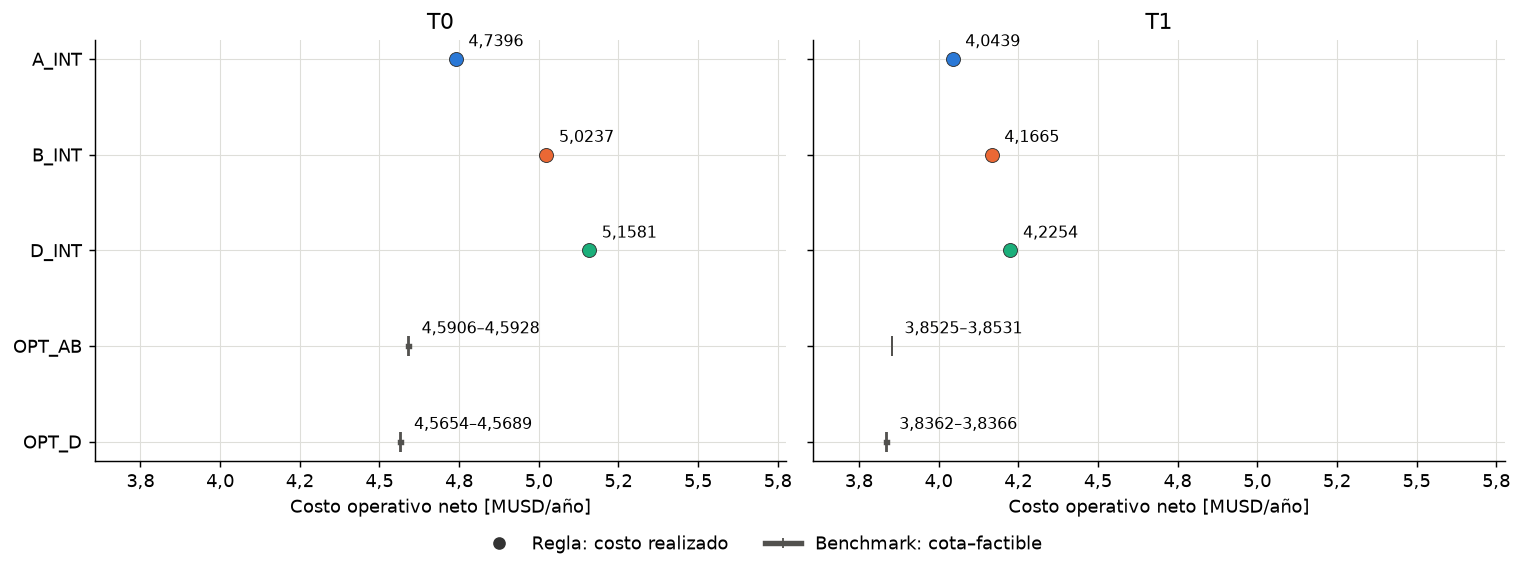

Señal,Regla,Benchmark,Distancia [mil USD/año],Distancia [%]
T0,A_INT,OPT_AB,"146,87–149,01","3,19–3,25"
T0,B_INT,OPT_AB,"430,94–433,08","9,38–9,44"
T0,D_INT,OPT_D,"589,23–592,62","12,89–12,99"
T1,A_INT,OPT_AB,"190,84–191,27","4,95–4,97"
T1,B_INT,OPT_AB,"313,48–313,91","8,13–8,15"
T1,D_INT,OPT_D,"388,77–389,10","10,13–10,15"


In [4]:
econ=RES.reset_index()[['Senal','Caso','Costo_realizado_USD','Cota_USD','Arranques']].copy()
econ['Costo o intervalo [MUSD/año]']=econ.apply(lambda r:es(r.Costo_realizado_USD/1e6,4)
    if r.Caso in REGLAS else intervalo(r.Cota_USD/1e6,r.Costo_realizado_USD/1e6,4),axis=1)
tabla(econ[['Senal','Caso','Costo o intervalo [MUSD/año]','Arranques']].rename(columns={'Senal':'Señal'}),4)
fig,axs=plt.subplots(1,2,figsize=(11.6,4.3),sharex=True,sharey=True,layout='constrained')
for ax,s in zip(axs,SENALES):
    for j,c in enumerate(CASOS):
        r=RES.loc[s,c]; x=r.Costo_realizado_USD/1e6
        if c in REGLAS:
            ax.scatter(x,j,color=COLOR[c],s=60,edgecolors='#333333',linewidths=.5,zorder=3)
            ax.annotate(es(x,4),(x,j),xytext=(7,7),textcoords='offset points',fontsize=9)
        else:
            lo=r.Cota_USD/1e6
            ax.plot([lo,x],[j,j],color=COLOR[c],lw=3,marker='|',ms=11)
            ax.annotate(intervalo(lo,x,4),(x,j),xytext=(7,7),textcoords='offset points',fontsize=9)
    ax.set(title=s,xlabel='Costo operativo neto [MUSD/año]',yticks=range(5),yticklabels=CASOS,xlim=(float(econ.Cota_USD.fillna(econ.Costo_realizado_USD).min())/1e6*.94,
        float(econ.Costo_realizado_USD.max())/1e6*1.12))
    ax.xaxis.set_major_formatter(FORMATO)
axs[0].invert_yaxis()
fig.legend(handles=[Line2D([],[],marker='o',color='#333333',ls='',label='Regla: costo realizado'),
                    Line2D([],[],color='#52514e',lw=3,marker='|',label='Benchmark: cota–factible')],
           loc='outside lower center',ncol=2,frameon=False)
guardar(fig,'14_1_costos_y_cotas')
distancias=GAP[['Senal','Politica','Benchmark']].rename(columns={'Senal':'Señal','Politica':'Regla'}).copy()
distancias['Distancia [mil USD/año]']=[intervalo(r.Distancia_min_USD/1000,r.Distancia_max_USD/1000) for r in GAP.itertuples()]
distancias['Distancia [%]']=[intervalo(r.Distancia_min_pct,r.Distancia_max_pct) for r in GAP.itertuples()]
tabla(distancias)

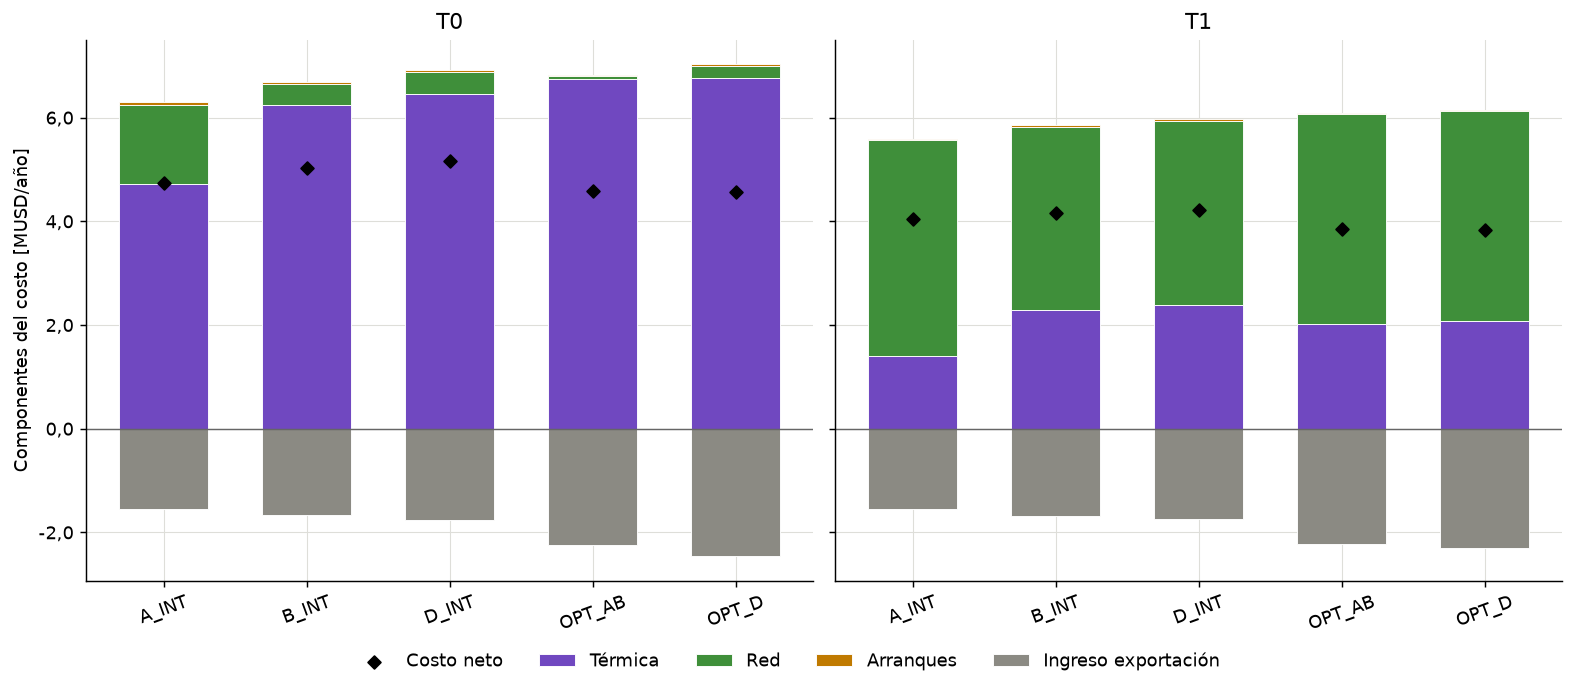

Senal,Comparacion,Combustible_CVOM_USD,Red_USD,Arranques_USD,Ingreso_exportacion_USD,Costo_realizado_USD
T0,B_INT − A_INT,"1.509.204,22","-1.096.636,81","-12.000,00","116.496,94","284.070,47"
T0,D_INT − B_INT,"214.084,55","15.401,04","500,00","95.591,87","134.393,71"
T1,B_INT − A_INT,"900.860,95","-654.560,08","5.800,00","129.460,71","122.640,17"
T1,D_INT − B_INT,"89.811,33","28.332,58","1.000,00","60.279,10","58.864,82"


In [5]:
componentes=[('Combustible_CVOM_USD','Térmica','#7048c0'),('Red_USD','Red','#3f8f3a'),
             ('Arranques_USD','Arranques','#c07a00'),('Ingreso_exportacion_USD','Ingreso exportación','#8b8a83')]
fig,axs=plt.subplots(1,2,figsize=(12,5.2),sharey=True,layout='constrained')
for ax,s in zip(axs,SENALES):
    r=RES.loc[s].loc[list(CASOS)]; piso=np.zeros(5); xs=np.arange(5)
    for key,label,color in componentes:
        y=r[key].to_numpy()/1e6
        if key=='Ingreso_exportacion_USD':
            ax.bar(xs,-y,.62,color=color,edgecolor='white',lw=.5,label=label)
        else:
            ax.bar(xs,y,.62,bottom=piso,color=color,edgecolor='white',lw=.5,label=label)
            piso+=y
    neto=r.Costo_realizado_USD.to_numpy()/1e6
    ax.scatter(xs,neto,c='black',marker='D',s=25,zorder=5,label='Costo neto')
    ax.axhline(0,c='#666666',lw=.8)
    ax.set(title=s,xticks=xs,xticklabels=CASOS)
    ax.tick_params(axis='x',rotation=20)
    ax.yaxis.set_major_formatter(FORMATO)
axs[0].set_ylabel('Componentes del costo [MUSD/año]')
fig.legend(*axs[0].get_legend_handles_labels(),loc='outside lower center',ncol=5,frameon=False)
guardar(fig,'14_2_componentes_costo')

diferencias=[]
for s in SENALES:
    for c,base in (('B_INT','A_INT'),('D_INT','B_INT')):
        a,b=RES.loc[s,c],RES.loc[s,base]
        fila=dict(Senal=s,Comparacion=f'{c} − {base}')
        for key in ('Combustible_CVOM_USD','Red_USD','Arranques_USD','Ingreso_exportacion_USD','Costo_realizado_USD'):
            fila[key]=a[key]-b[key]
        assert abs(fila['Combustible_CVOM_USD']+fila['Red_USD']+fila['Arranques_USD']-
                   fila['Ingreso_exportacion_USD']-fila['Costo_realizado_USD'])<1e-6
        diferencias.append(fila)
DIF=pd.DataFrame(diferencias)
tabla(DIF,2)
DIF.to_csv(OUT/'14_diferencias_costo.csv',index=False)

El ingreso aparece con signo negativo en el costo. En la tabla de diferencias,
un aumento del ingreso se muestra positivo y **se resta** al reconstruir la diferencia neta.
Así se puede comprobar qué ahorro compensa —o no— la mayor generación térmica.

## 5 · Operación: arranques, batería y rutas de energía

Se reportan conjuntamente costo y ciclados; reducir arranques no garantiza reducir el costo.
G1/G2 se agrupan porque son unidades idénticas y su reparto individual puede cambiar entre
óptimos alternativos.

**EFC útil, entrega AC** = descarga anual total del BESS / 224 MWh, manteniendo la convención
contable de la comparación previa. Incluye descarga hacia demanda y exportación. No es una
predicción de vida: en el lado del SOC el throughput sería la descarga dividida por η_d.
**Cobertura solar de la demanda** = (PV directo + descarga BESS a demanda) / demanda.
Toda la carga es solar y el SOC cierra; esa cobertura incluye la energía solar almacenada.
Exportar y evitar vertimiento son indicadores distintos del autoconsumo.

Senal,Caso,Arranques,EFC_util_entrega_AC,Cobertura_demanda_solar_pct,Termica_MWh,Red_MWh
T0,A_INT,578,"291,82","80,72","23.395,31","7.202,92"
T0,B_INT,458,"281,85","79,32","30.865,13","1.966,61"
T0,D_INT,463,"297,18","78,60","31.924,75","2.040,28"
T0,OPT_AB,361,"278,30","78,82","33.386,72","240,33"
T0,OPT_D,360,"282,57","78,22","33.497,21","1.072,04"
T1,A_INT,245,"291,82","80,72","6.805,42","23.792,81"
T1,B_INT,303,"286,23","79,94","11.337,91","20.513,74"
T1,D_INT,313,"296,01","79,56","11.782,25","20.668,23"
T1,OPT_AB,114,"278,48","78,84","9.975,28","23.611,38"
T1,OPT_D,118,"283,09","78,65","10.264,06","23.624,12"


Senal,Caso,Carga_BESS_MWh,Descarga_demanda_MWh,Export_BESS_MWh,Export_PV_MWh,Perdidas_BESS_MWh,Vertimiento_MWh
T0,A_INT,"72.631,92","65.368,72","0,00","23.335,03","7.263,19","0,00"
T0,B_INT,"70.150,23","63.135,21","0,00","25.816,72","7.015,02","0,00"
T0,D_INT,"73.966,02","62.001,92","4.567,50","22.000,93","7.396,60","0,00"
T0,OPT_AB,"69.266,56","62.339,90","0,00","26.700,39","6.926,66","-0,00"
T0,OPT_D,"70.329,26","61.397,71","1.898,62","25.637,69","7.032,93","-0,00"
T1,A_INT,"72.631,92","65.368,72","0,00","23.335,03","7.263,19","0,00"
T1,B_INT,"71.239,23","64.115,30","0,00","24.727,72","7.123,92","0,00"
T1,D_INT,"73.673,86","63.516,48","2.790,00","22.293,09","7.367,39","0,00"
T1,OPT_AB,"69.311,44","62.380,29","0,00","26.655,52","6.931,14","-0,00"
T1,OPT_D,"70.457,58","62.078,77","1.333,05","25.509,37","7.045,76","-0,00"


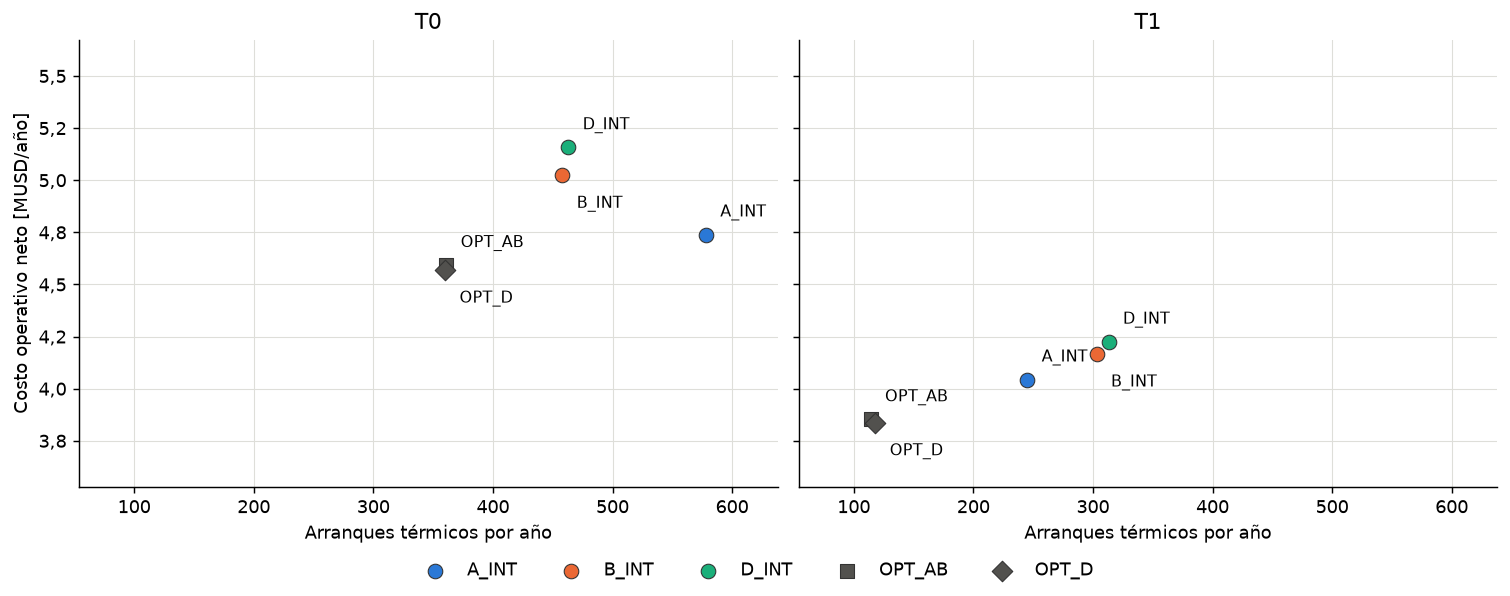

In [6]:
operacion=[]
for s in SENALES:
    for c in CASOS:
        r=RES.loc[s,c]; z=DAT[s,c]
        perdidas=float(z['Carga_BESS'].sum()-z['Descarga_demanda'].sum()-z['Descarga_export'].sum())
        balance=float(z['PV_directo'].sum()+z['Descarga_demanda'].sum()+z['Export_PV'].sum()+
                      z['Descarga_export'].sum()+z['Vertimiento'].sum()+perdidas-z['PV'].sum())
        assert perdidas>=-1e-5 and abs(balance)<=1e-5
        operacion.append(dict(Senal=s,Caso=c,Arranques=int(r.Arranques),
            Arranques_G1_G2=int(r.Arranques_G1_G2),Arranques_G3=int(r.Arranques_G3),Arranques_G4=int(r.Arranques_G4),
            EFC_util_entrega_AC=r.Descarga_BESS_MWh/EUTIL,
            Cobertura_demanda_solar_pct=100*(r.PV_directo_MWh+r.Descarga_demanda_MWh)/z['Carga'].sum(),
            Termica_MWh=r.Termica_MWh,Red_MWh=r.Red_MWh,Carga_BESS_MWh=r.Carga_BESS_MWh,
            Descarga_demanda_MWh=r.Descarga_demanda_MWh,Export_BESS_MWh=r.Descarga_export_MWh,
            Export_PV_MWh=r.Export_PV_MWh,Perdidas_BESS_MWh=perdidas,Vertimiento_MWh=r.Vertimiento_MWh))
OPE=pd.DataFrame(operacion)
tabla(OPE[['Senal','Caso','Arranques','EFC_util_entrega_AC','Cobertura_demanda_solar_pct','Termica_MWh','Red_MWh']],2)
tabla(OPE[['Senal','Caso','Carga_BESS_MWh','Descarga_demanda_MWh','Export_BESS_MWh','Export_PV_MWh','Perdidas_BESS_MWh','Vertimiento_MWh']],2)
OPE.to_csv(OUT/'14_indicadores_operacion.csv',index=False)

fig,axs=plt.subplots(1,2,figsize=(11.5,4.5),sharey=True,sharex=True,layout='constrained')
for ax,s in zip(axs,SENALES):
    for c in CASOS:
        r=RES.loc[s,c]; x=r.Arranques; y=r.Costo_realizado_USD/1e6
        marker='o' if c in REGLAS else ('s' if c=='OPT_AB' else 'D')
        ax.scatter(x,y,s=65,marker=marker,c=COLOR[c],edgecolors='#333333',linewidths=.6,zorder=3,label=c)
        offset=(8,-18) if c in ('B_INT','OPT_D') else (8,10)
        ax.annotate(c,(x,y),xytext=offset,textcoords='offset points',fontsize=9)
    ax.set(title=s,xlabel='Arranques térmicos por año',xlim=(max(0.,float(RES.Arranques.min())-60),float(RES.Arranques.max())+60),
        ylim=(float(RES.Costo_realizado_USD.min())/1e6*.92,float(RES.Costo_realizado_USD.max())/1e6*1.10))
    ax.yaxis.set_major_formatter(FORMATO)
axs[0].set_ylabel('Costo operativo neto [MUSD/año]')
fig.legend(*axs[0].get_legend_handles_labels(),loc='outside lower center',ncol=5,frameon=False)
guardar(fig,'14_3_costo_y_arranques')

## 6 · Referencia sin almacenamiento y beneficio capturado

SIN_BESS comparte las entradas, las restricciones térmicas y la exportación PV del estudio.
La exclusión carga/descarga no tiene efecto al no existir batería; tampoco aplica frontera
de SOC. Su solución anual tiene una cota inferior y una superior que se conservan al calcular ahorros.

El ahorro frente a esa referencia incluye el almacenamiento **operado por la política** frente
a un sistema sin batería con despacho térmico anual. No es el beneficio aislado de cambiar la
regla ni una rentabilidad de inversión.

La captura relativa es (C_sin − C_regla)/(C_sin − C_óptimo compatible). Se acota evaluando
las esquinas de los intervalos de ambos benchmarks, siempre que los denominadores sean positivos.
Su denominador es el ahorro alcanzable: no equivale a 100 % menos la brecha relativa de costo.
La comparación OPT_AB − OPT_D mide el valor de **permitir** exportación del BESS; la comparación
D_INT − B_INT mide el resultado de las implementaciones heurísticas.

In [7]:
ahorros=[]
for s in SENALES:
    base=ANT.loc[s,'SIN_BESS']; blo=float(base.Cota_USD); bhi=float(base.Costo_operativo_neto_USD)
    assert blo<=bhi+1e-3
    for c,bench in (('A_INT','OPT_AB'),('B_INT','OPT_AB'),('D_INT','OPT_D')):
        cp=RES.loc[s,c].Costo_realizado_USD; opt=RES.loc[s,bench]
        lo,hi=opt.Cota_USD,opt.Costo_realizado_USD
        assert blo>hi and cp>=hi
        capturas=[100*(b0-cp)/(b0-o0) for b0 in (blo,bhi) for o0 in (lo,hi)]
        ahorros.append(dict(Senal=s,Caso=c,Benchmark=bench,SIN_BESS_cota_USD=blo,SIN_BESS_factible_USD=bhi,
            Ahorro_min_USD=blo-cp,Ahorro_max_USD=bhi-cp,
            Captura_min_pct=min(capturas),Captura_max_pct=max(capturas)))
AHO=pd.DataFrame(ahorros)
vista=AHO[['Senal','Caso','Benchmark']].rename(columns={'Senal':'Señal'}).copy()
vista['Ahorro [MUSD/año]']=[intervalo(r.Ahorro_min_USD/1e6,r.Ahorro_max_USD/1e6,4) for r in AHO.itertuples()]
vista['Captura [%]']=[intervalo(r.Captura_min_pct,r.Captura_max_pct) for r in AHO.itertuples()]
tabla(vista)
vex=pd.DataFrame({'Señal':VALOR.Senal,'Valor de permitir exportación [mil USD/año]':
    [intervalo(r.Valor_exportacion_min_USD/1000,r.Valor_exportacion_max_USD/1000) for r in VALOR.itertuples()]})
tabla(vex)
AHO.to_csv(OUT/'14_ahorro_y_captura.csv',index=False)

Señal,Caso,Benchmark,Ahorro [MUSD/año],Captura [%]
T0,A_INT,OPT_AB,"9,9576–9,9577","98,52–98,55"
T0,B_INT,OPT_AB,"9,6735–9,6736","95,71–95,74"
T0,D_INT,OPT_D,"9,5391–9,5392","94,15–94,19"
T1,A_INT,OPT_AB,"9,1277–9,1278","97,94–97,96"
T1,B_INT,OPT_AB,"9,0051–9,0052","96,63–96,64"
T1,D_INT,OPT_D,"8,9462–8,9463","95,83–95,84"


Señal,Valor de permitir exportación [mil USD/año]
T0,"21,76–27,29"
T1,"16,00–16,75"


## 7 · Una semana de producción solar intermedia

**Selección independiente del resultado económico:** se toman semanas completas de lunes a domingo
y se elige la de energía PV más cercana a la mediana; ante empate, la primera cronológicamente.
La misma semana se muestra en T0 y T1. Es un ejemplo descriptivo, no una muestra estadística ni
evidencia de comportamiento en todas las estaciones. Las gráficas muestran fragmentos de las
trayectorias anuales: no se vuelve a inicializar el SOC ni el compromiso térmico.

Los tres paneles superiores descomponen cómo se atiende la demanda. El inferior compara el SOC.
La exportación se informa aparte porque no atiende demanda; así no se confunde con descarga útil
para el usuario. Los costos de la semana son sumas contables de la trayectoria anual, no el resultado
de optimizar o simular la semana por separado.

Semana seleccionada: **21/04/2025–27/04/2025**. PV: **3.069,53 MWh**; mediana de semanas completas: 3.069,53 MWh.

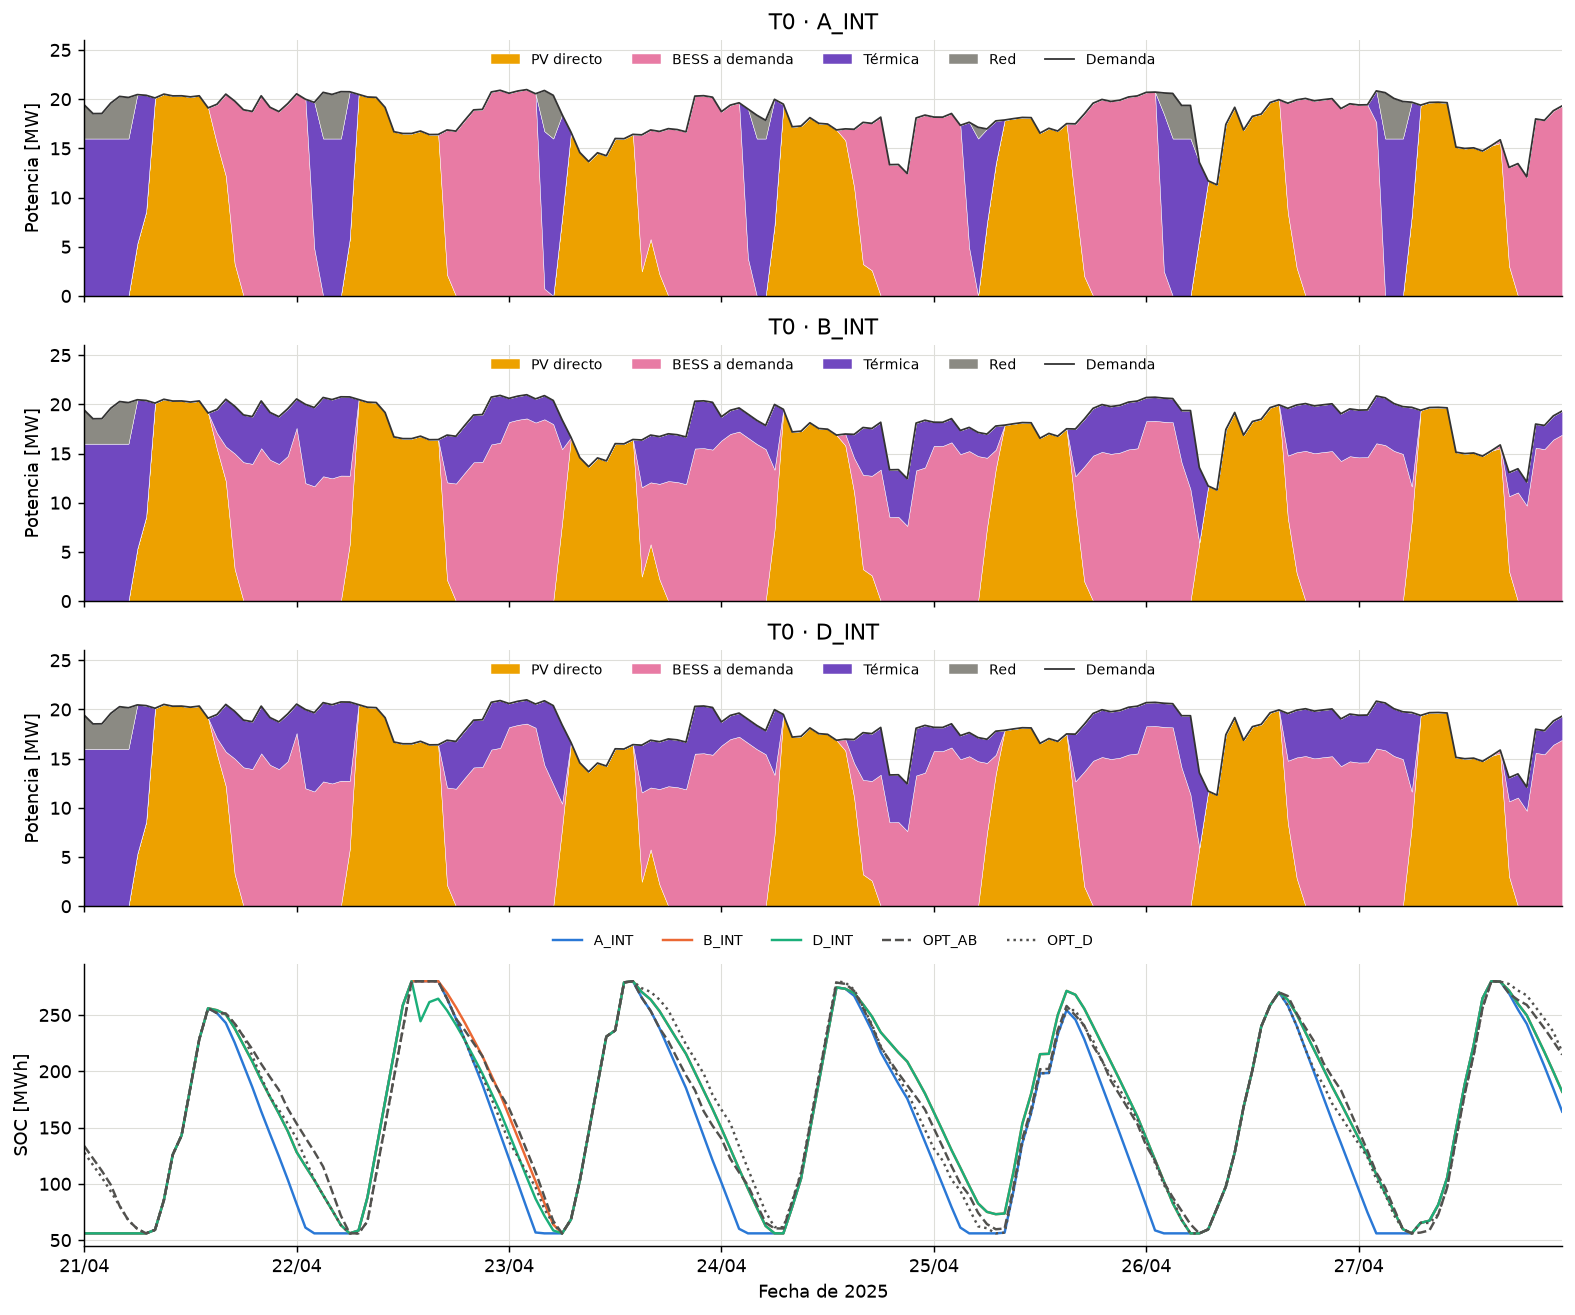

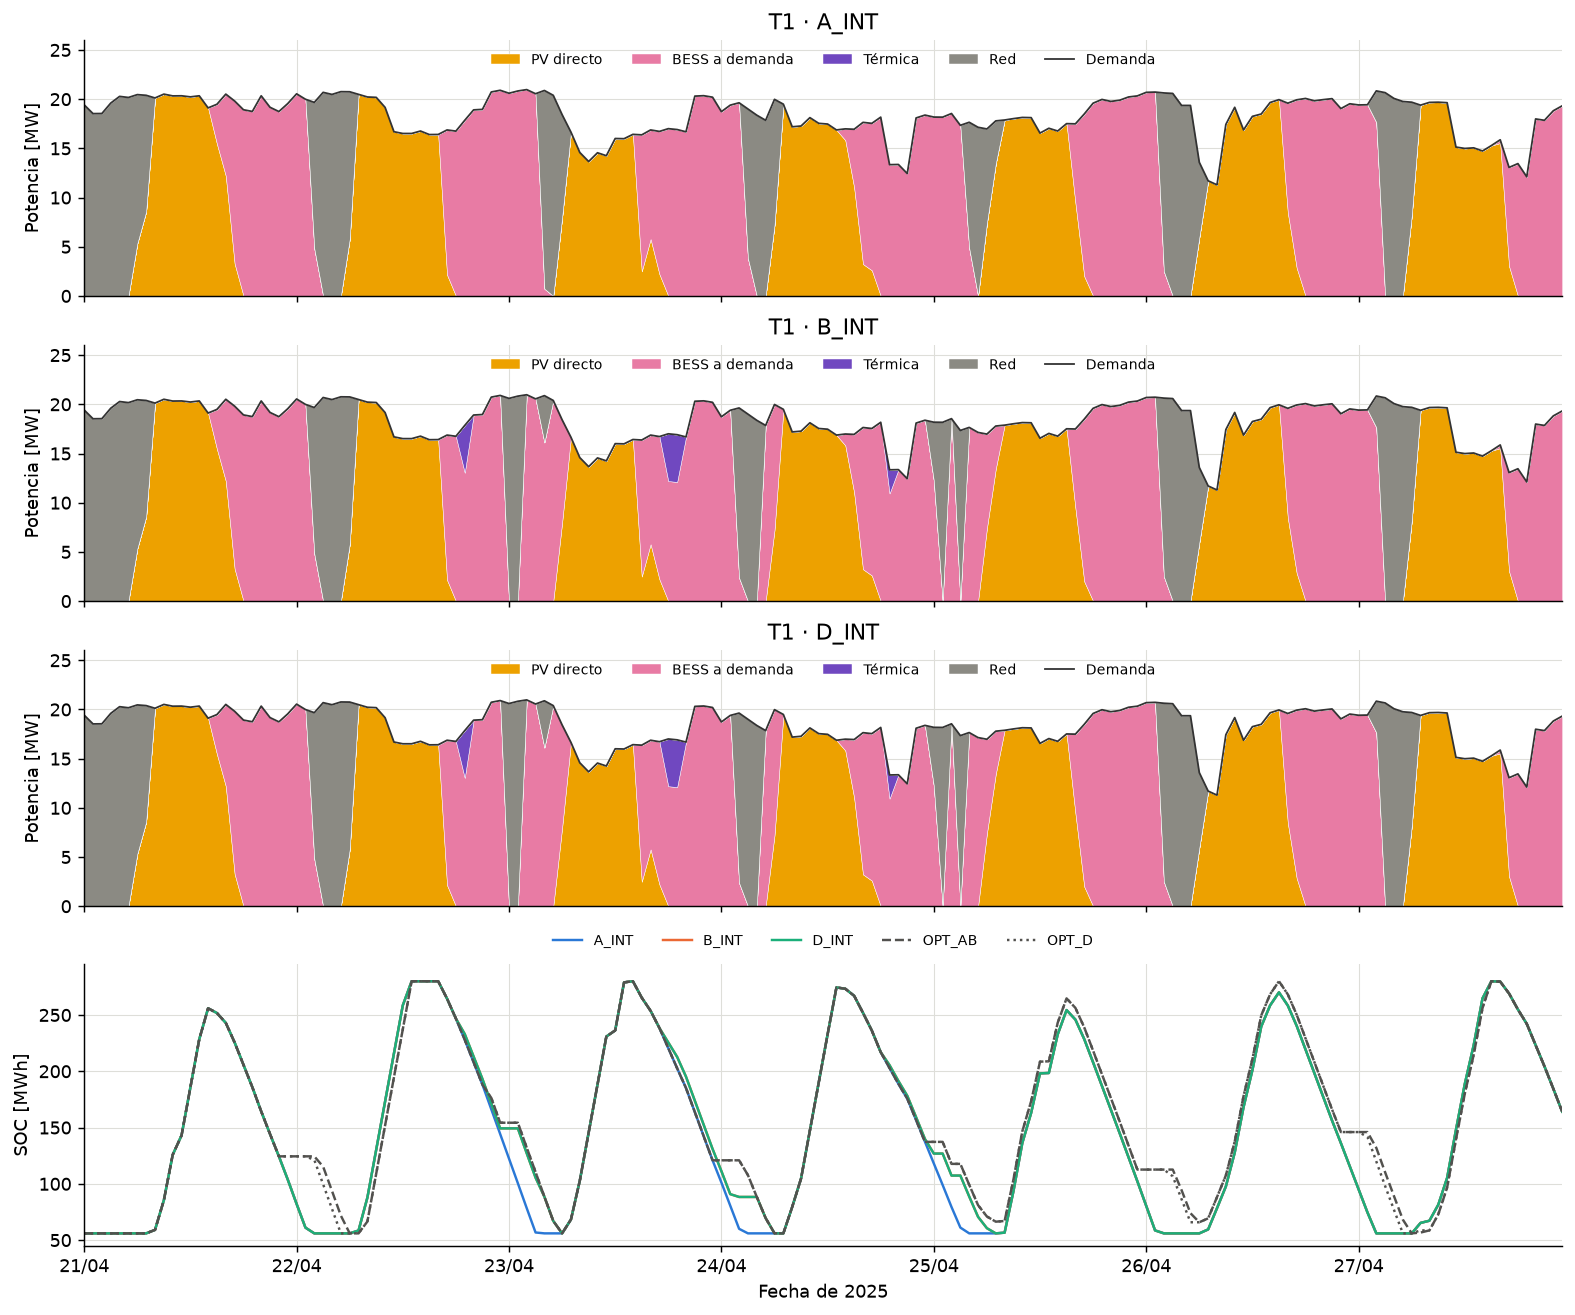

Senal,Caso,Inicio,Fin_exclusivo,Costo_USD,Arranques,Termica_MWh,Red_MWh,Descarga_demanda_MWh,Export_BESS_MWh
T0,A_INT,2025-04-21 00:00:00,2025-04-28 00:00:00,"110.351,26",14,"480,22","74,36","1.323,25","0,00"
T0,B_INT,2025-04-21 00:00:00,2025-04-28 00:00:00,"112.673,25",7,"550,81","20,58","1.306,45","0,00"
T0,D_INT,2025-04-21 00:00:00,2025-04-28 00:00:00,"115.493,46",7,"565,55","20,58","1.291,71","33,75"
T1,A_INT,2025-04-21 00:00:00,2025-04-28 00:00:00,"89.046,37",0,"0,00","554,59","1.323,25","0,00"
T1,B_INT,2025-04-21 00:00:00,2025-04-28 00:00:00,"89.724,92",3,"16,80","537,79","1.323,25","0,00"
T1,D_INT,2025-04-21 00:00:00,2025-04-28 00:00:00,"89.724,92",3,"16,80","537,79","1.323,25","0,00"


In [8]:
serie_pv=pd.Series(DAT['T0','A_INT']['PV'],index=FECHAS)
semanas=serie_pv.resample('W-MON',closed='left',label='left').agg(['sum','count'])
semanas=semanas[semanas['count']==168].copy()
mediana=float(semanas['sum'].median())
inicio=(semanas['sum']-mediana).abs().idxmin(); fin=inicio+pd.Timedelta(days=7)
mask=(FECHAS>=inicio)&(FECHAS<fin); fechas=FECHAS[mask]
assert mask.sum()==168
display(Markdown(f'Semana seleccionada: **{inicio:%d/%m/%Y}–{(fin-pd.Timedelta(days=1)):%d/%m/%Y}**. '
                 f'PV: **{es(semanas.loc[inicio,"sum"])} MWh**; mediana de semanas completas: {es(mediana)} MWh.'))
sem=[]
for s in SENALES:
    fig,axs=plt.subplots(4,1,figsize=(12,10),sharex=True,layout='constrained',gridspec_kw={'height_ratios':[1,1,1,1.1]})
    for ax,c in zip(axs[:3],REGLAS):
        z=DAT[s,c]; p=z['potencia'][mask]
        partes=[z['PV_directo'][mask],z['Descarga_demanda'][mask],p[:,:4].sum(axis=1),p[:,4]]
        ax.stackplot(fechas,*partes,labels=['PV directo','BESS a demanda','Térmica','Red'],
                     colors=['#eda100','#e87ba4','#7048c0','#8b8a83'],linewidth=.25,edgecolor='white')
        ax.plot(fechas,z['Carga'][mask],color='#333333',lw=1,label='Demanda')
        ax.set(title=f'{s} · {c}',ylabel='Potencia [MW]',ylim=(0,26))
        ax.legend(loc='upper center',ncol=5,fontsize=8,frameon=False)
        ct=float(np.sum(p[:,:4]*P['cv'])+p[:,4]@z['C_imp_USD'][mask]+
            z['arranques'][mask].sum()*META['cargo_arranque_USD']-
            (z['Export_PV'][mask]+z['Descarga_export'][mask])@z['C_exp_USD'][mask])
        sem.append(dict(Senal=s,Caso=c,Inicio=str(inicio),Fin_exclusivo=str(fin),Costo_USD=ct,
            Arranques=int(z['arranques'][mask].sum()),Termica_MWh=float(p[:,:4].sum()),Red_MWh=float(p[:,4].sum()),
            Descarga_demanda_MWh=float(z['Descarga_demanda'][mask].sum()),
            Export_BESS_MWh=float(z['Descarga_export'][mask].sum())))
    for c in CASOS:
        ls='-' if c in REGLAS else ('--' if c=='OPT_AB' else ':')
        axs[3].plot(fechas,DAT[s,c]['SOC'][mask],color=COLOR[c],ls=ls,lw=1.35,label=c)
    axs[3].set(ylabel='SOC [MWh]',ylim=(45,295))
    axs[3].legend(loc='lower center',bbox_to_anchor=(.5,1.01),ncol=5,fontsize=8,frameon=False)
    axs[3].xaxis.set_major_locator(mdates.DayLocator())
    axs[3].xaxis.set_major_formatter(mdates.DateFormatter('%d/%m'))
    axs[3].set_xlim(fechas[0],fechas[-1]); axs[3].set_xlabel('Fecha de 2025')
    guardar(fig,f'14_4_semana_{s}')
SEM=pd.DataFrame(sem)
tabla(SEM,2)
SEM.to_csv(OUT/'14_semana_ejemplo.csv',index=False)

## 8 · Hallazgos para la discusión de la tesis

El cierre físico permite comparar trayectorias factibles; no demuestra que una heurística sea
la mejor posible de su familia. El orden de las 72 horas de enero no se mantiene al ampliar el
horizonte al año. Los resultados anuales de estas implementaciones son la evidencia principal.

In [9]:
parrafos=[]
for s in SENALES:
    a,b,d=(RES.loc[s,c] for c in REGLAS)
    orden=RES.loc[s].loc[list(REGLAS),'Costo_realizado_USD'].sort_values().index.tolist()
    parrafos.append(f'**{s}.** Orden de menor a mayor costo: {", ".join(orden)}. '
        f'Diferencia B_INT − A_INT: {es(b.Costo_realizado_USD-a.Costo_realizado_USD)} USD '
        f'y {int(b.Arranques-a.Arranques):+d} arranques. '
        f'Diferencia D_INT − B_INT: {es(d.Costo_realizado_USD-b.Costo_realizado_USD)} USD; '
        f'exportación del BESS en D: {es(d.Descarga_export_MWh)} MWh.')
display(Markdown('\n\n'.join(parrafos)))

**T0.** Orden de menor a mayor costo: A_INT, B_INT, D_INT. Diferencia B_INT − A_INT: 284.070,47 USD y -120 arranques. Diferencia D_INT − B_INT: 134.393,71 USD; exportación del BESS en D: 4.567,50 MWh.

**T1.** Orden de menor a mayor costo: A_INT, B_INT, D_INT. Diferencia B_INT − A_INT: 122.640,17 USD y +58 arranques. Diferencia D_INT − B_INT: 58.864,82 USD; exportación del BESS en D: 2.790,00 MWh.

**Interpretación respaldada por los balances económicos.** Las diferencias de costo
se descomponen en térmica, red, arranques e ingresos de exportación. El orden se calcula
desde las nuevas trayectorias, sin imponer el observado con el gas anterior. D_INT − B_INT
describe el desempeño de las heurísticas; el intervalo OPT_AB − OPT_D mide el valor
potencial de permitir exportar energía del BESS.

**Alcance metodológico.** B conserva una pasada y un conjunto limitado de candidatos; puede mantener
unidades en mínimos aun con energía de batería disponible. D hereda esa limitación y usa cantidades
finitas de exportación. Estas son propiedades de las implementaciones evaluadas. No se atribuye
toda la brecha a una sola limitación, ni se modifica la regla para imponer un resultado esperado.

**Límites de las conclusiones.** Caso base, tamaños fijos, información diaria/anual perfecta según
el método, costo de arranque supuesto y desempeño térmico sin calibración operativa de planta.
El EFC se reporta como indicador; el envejecimiento y la inversión no están monetizados en este
despacho, por lo que no se concluye sobre VPN, reposiciones o rentabilidad. Solo el SOC es cíclico.
Cada benchmark conserva su cota, solución factible y condición del solver. La serie solar procede de un
año meteorológico típico; no se presenta como medición solar de la planta en 2025.

El bloque adicional C/F se incorpora a continuación. La trazabilidad técnica está en
`REGLAS_TERMICA.md` y `POLITICAS_CF.md`; se utilizan únicamente identificadores G1–G4.

## 9 · Bloque adicional C/F y comparación conjunta

| Regla | Decisión adicional | Referencia compatible |
|---|---|---|
| C_INT | Compra de red en horas elegibles y descarga según mérito conjunto y filtro diario | OPT_CF |
| F_INT | C con presupuesto de compra que reserva capacidad para excedentes PV | OPT_CF |

C/F y OPT_CF permiten carga de red; A/B/D y OPT_AB/OPT_D cargan solo de PV.
Todos priorizan PV directo, conservan tamaños y parámetros, y prohíben que la
térmica cargue el BESS o exporte. Los cuartiles, candidatos finitos y presupuesto
de F pertenecen a las heurísticas: el benchmark no los impone.

La fuente adicional es `resultados_correccion_numerica/20260920/anual_cf/`. Se comprueban
seis trayectorias nuevas (C/F/OPT_CF × T0/T1), además de las doce anteriores.
OPT_D es el mismo resultado reutilizado, no otra corrida. Las seis pertenencias
adicionales fijan C, F y OPT_D dentro de OPT_CF. Los certificados fijados pueden
ser óptimos sin que ello demuestre la optimalidad del problema anual libre.

In [10]:
MCF=json.loads((SAL_CF/'ejecucion.json').read_text(encoding='utf-8'),object_hook=decodificar)
for k in ('pmin','pmax','hr','cvom','cv'):
    np.testing.assert_array_equal(MCF['parametros_termicos'][k],P[k])
assert MCF['bess']==B and MCF['parametros_termicos']['gas']==P['gas']
assert MCF['cargo_arranque_USD']==META['cargo_arranque_USD']
assert MCF['P_EXP_MAX']==META['P_EXP_MAX'] and MCF['horas']==8760
RCF=pd.read_csv(SAL_CF/'resumen.csv',float_precision='round_trip').set_index(['Senal','Caso'])
PCF=pd.read_csv(SAL_CF/'pertenencia.csv',float_precision='round_trip')
GCF=pd.read_csv(SAL_CF/'comparacion.csv',float_precision='round_trip')
VCF=pd.read_csv(SAL_CF/'valor_carga_red.csv',float_precision='round_trip')
assert len(PCF)==6 and PCF.Estado.eq('OK').all()
assert (PCF.Diferencia_USD<=PCF.Banda_objetivo_USD).all()
assert set(zip(PCF.Senal,PCF.Caso))=={(s,c) for s in SENALES for c in ('C_INT','F_INT','OPT_D')}
assert len(GCF)==4 and len(VCF)==2
CONJUNTOS=('A_INT','B_INT','D_INT','C_INT','F_INT','OPT_AB','OPT_D','OPT_CF')
POLITICAS=CONJUNTOS[:5]
TODOS=dict(DAT); AUD_CF=[]
for s in SENALES:
    reutilizado=leer(SAL_CF/f'{s}_OPT_D.npz')
    for k,v in DAT[s,'OPT_D'].items():
        np.testing.assert_array_equal(reutilizado[k],v,err_msg=f'OPT_D reutilizado: {k}')
    for c in ('C_INT','F_INT','OPT_CF'):
        z=leer(SAL_CF/f'{s}_{c}.npz'); TODOS[s,c]=z
        auditar(s,c,z,resumen_cf=RCF.loc[s,c],registros=AUD_CF)
        assert abs(float(z['SOC'][-1]-z['SOC_inicial']))<=MCF['tol_ciclo']
        neto=B['eta_c']*math.fsum(z['Carga_BESS'])-math.fsum((z['Descarga_demanda']+z['Descarga_export'])/B['eta_d'])
        assert abs(neto-float(z['SOC'][-1]-z['SOC_inicial']))<=1e-5
        if c in ('C_INT','F_INT'):
            assert RCF.loc[s,c].Estado_ciclo=='CONVERGE'
            # Prioridad de la carga solar ejecutada por las reglas C/F.
            previo=np.r_[float(z['SOC_inicial']),z['SOC'][:-1]]
            solar=np.minimum.reduce([np.maximum(z['PV']-z['Carga'],0),
                np.full(8760,B['P_MW']),np.maximum(B['E_MWh']*B['soc_max_pu']-previo,0)/B['eta_c']])
            np.testing.assert_allclose(z['Carga_PV'],solar,rtol=0,atol=1e-6)
CF_IDENTICAS={s:all(np.array_equal(TODOS[s,'C_INT'][k],TODOS[s,'F_INT'][k])
    for k in TODOS[s,'C_INT']) for s in SENALES}
AUD_TOTAL=pd.concat([AUD,pd.DataFrame(AUD_CF)],ignore_index=True)
assert len(AUD_TOTAL)==18 and AUD_TOTAL.Estado.eq('OK').all()
AUD_TOTAL.to_csv(OUT/'14_validaciones_conjuntas.csv',index=False)

COM=pd.read_csv(ANA_CF/'resumen_ampliado.csv',float_precision='round_trip').set_index(['Senal','Caso'])
assert set(COM.index)==set(TODOS) and COM.Horas.eq(8760).all()
for (s,c),z in TODOS.items():
    p=z['potencia']; r=COM.loc[s,c]
    solar=z.get('Carga_PV',z['Carga_BESS']); red=z.get('Carga_Red',np.zeros(8760))
    valores=dict(Costo_USD=float(z['Objetivo']),Costo_termico_USD=np.sum(p[:,:4]*P['cv']),
        Costo_red_demanda_USD=p[:,4]@z['C_imp_USD'],Costo_red_BESS_USD=red@z['C_imp_USD'],
        Costo_arranques_USD=z['arranques'].sum()*META['cargo_arranque_USD'],
        Ingreso_exportacion_USD=(z['Export_PV']+z['Descarga_export'])@z['C_exp_USD'],
        Arranques=z['arranques'].sum(),Termica_MWh=p[:,:4].sum(),Red_demanda_MWh=p[:,4].sum(),
        Carga_red_MWh=red.sum(),Carga_PV_MWh=solar.sum(),Descarga_demanda_MWh=z['Descarga_demanda'].sum(),
        Descarga_export_MWh=z['Descarga_export'].sum(),Export_PV_MWh=z['Export_PV'].sum(),
        Vertimiento_MWh=z['Vertimiento'].sum(),SOC_inicial_MWh=float(z['SOC_inicial']),SOC_final_MWh=z['SOC'][-1])
    previo=np.r_[float(z['SOC_inicial']),z['SOC'][:-1]]
    sin_descarga=((z['Carga']-z['PV_directo']>1e-6)&(z['Descarga_demanda']<=1e-6)
                  &(previo>B['E_MWh']*B['soc_min_pu']+1e-6))
    valores['Horas_deficit_SOC_sin_descarga']=int(sin_descarga.sum())
    for k,v in valores.items():
        assert abs(r[k]-v)<=1e-5,(s,c,k,r[k],v)
    assert abs(r.Costo_USD-(r.Costo_termico_USD+r.Costo_red_demanda_USD+r.Costo_red_BESS_USD+
        r.Costo_arranques_USD-r.Ingreso_exportacion_USD))<=1e-5
    if c.startswith('OPT'):
        fuente=RCF.loc[s,c] if c=='OPT_CF' else RES.loc[s,c]
        for k in ('Cota_USD','Brecha_solver','Condicion'):
            assert r[k]==fuente[k],(s,c,k)
COM['Carga_total_MWh']=COM.Carga_PV_MWh+COM.Carga_red_MWh
COM['Importacion_total_MWh']=COM.Red_demanda_MWh+COM.Carga_red_MWh
COM['Exportacion_total_MWh']=COM.Export_PV_MWh+COM.Descarga_export_MWh
COM['Descarga_total_MWh']=COM.Descarga_demanda_MWh+COM.Descarga_export_MWh
COM['EFC_util_entrega_AC']=COM.Descarga_total_MWh/EUTIL
COM['Perdidas_BESS_MWh']=COM.Carga_total_MWh-COM.Descarga_total_MWh
COM['Arranques_G1_G2']=[int(TODOS[k]['arranques'][:,:2].sum()) for k in COM.index]
COM=COM.loc[pd.MultiIndex.from_product([SENALES,CONJUNTOS],names=['Senal','Caso'])]
COM.to_csv(OUT/'14_comparacion_conjunta.csv')
tabla(COM.reset_index()[['Senal','Caso','Costo_USD','Arranques','Carga_PV_MWh','Carga_red_MWh',
    'Descarga_demanda_MWh','Descarga_export_MWh','Importacion_total_MWh','Export_PV_MWh']],2)
print('18 trayectorias validadas y 12 pertenencias previas OK. Identidad C/F por señal:',CF_IDENTICAS)

Senal,Caso,Costo_USD,Arranques,Carga_PV_MWh,Carga_red_MWh,Descarga_demanda_MWh,Descarga_export_MWh,Importacion_total_MWh,Export_PV_MWh
T0,A_INT,"4.739.616,36",578,"72.631,92","0,00","65.368,72","0,00","7.202,92","23.335,03"
T0,B_INT,"5.023.686,82",458,"70.150,23","0,00","63.135,21","0,00","1.966,61","25.816,72"
T0,D_INT,"5.158.080,53",463,"73.966,02","0,00","62.001,92","4.567,50","2.040,28","22.000,93"
T0,C_INT,"11.367.008,46",678,"22.372,17","0,00","19.639,95","495,00","1.231,76","73.594,78"
T0,F_INT,"11.367.008,46",678,"22.372,17","0,00","19.639,95","495,00","1.231,76","73.594,78"
T0,OPT_AB,"4.592.743,20",361,"69.266,56","0,00","62.339,90","0,00","240,33","26.700,39"
T0,OPT_D,"4.568.850,31",360,"70.329,26","0,00","61.397,71","1.898,62","1.072,04","25.637,69"
T0,OPT_CF,"4.567.906,46",362,"70.328,97","104,94","61.397,45","1.993,06","1.030,59","25.637,98"
T1,A_INT,"4.043.858,38",245,"72.631,92","0,00","65.368,72","0,00","23.792,81","23.335,03"
T1,B_INT,"4.166.498,55",303,"71.239,23","0,00","64.115,30","0,00","20.513,74","24.727,72"


18 trayectorias validadas y 12 pertenencias previas OK. Identidad C/F por señal: {'T0': True, 'T1': False}


### 9.1 · Costo y precisión de la comparación

La tabla anterior conserva el **costo y operación de cada trayectoria guardada**.
La siguiente figura representa intervalos del costo óptimo. En OPT_CF se combina
su cota inferior con la mejor solución factible conocida entre OPT_CF, OPT_D, C y F,
indicando cuál la aporta. Las métricas operativas del solver conservan su propia
trayectoria. Una pertenencia factible no certifica el óptimo del problema libre.

Senal,Benchmark,Cota_USD,Costo_solver_USD,Mejor_factible_USD,Origen_mejor_factible,Condicion,Brecha_solver_pct
T0,OPT_AB,"4.590.616,1224","4.592.743,1980","4.592.743,1980",OPT_AB,ok/time_limit,"0,0463"
T0,OPT_D,"4.565.460,8269","4.568.850,3120","4.568.850,3120",OPT_D,ok/time_limit,"0,0742"
T0,OPT_CF,"4.564.334,4867","4.567.906,4590","4.567.906,4590",OPT_CF,ok/time_limit,"0,0782"
T1,OPT_AB,"3.852.591,1516","3.853.011,6112","3.853.011,6112",OPT_AB,ok/time_limit,"0,0109"
T1,OPT_D,"3.836.270,6200","3.836.587,2151","3.836.587,2151",OPT_D,ok/time_limit,"0,0083"
T1,OPT_CF,"3.816.300,6106","3.816.712,7838","3.816.712,7838",OPT_CF,ok/time_limit,"0,0108"


Senal,Politica,Benchmark,Distancia [mil USD],Distancia [%]
T0,A_INT,OPT_AB,"146,87–149,01","3,19–3,25"
T0,B_INT,OPT_AB,"430,94–433,08","9,38–9,44"
T0,D_INT,OPT_D,"589,23–592,62","12,89–12,99"
T0,C_INT,OPT_CF,"6.799,10–6.802,68","148,84–149,04"
T0,F_INT,OPT_CF,"6.799,10–6.802,68","148,84–149,04"
T1,A_INT,OPT_AB,"190,84–191,27","4,95–4,97"
T1,B_INT,OPT_AB,"313,48–313,91","8,13–8,15"
T1,D_INT,OPT_D,"388,77–389,10","10,13–10,15"
T1,C_INT,OPT_CF,"4.238,32–4.238,74","111,04–111,07"
T1,F_INT,OPT_CF,"4.238,55–4.238,98","111,05–111,08"


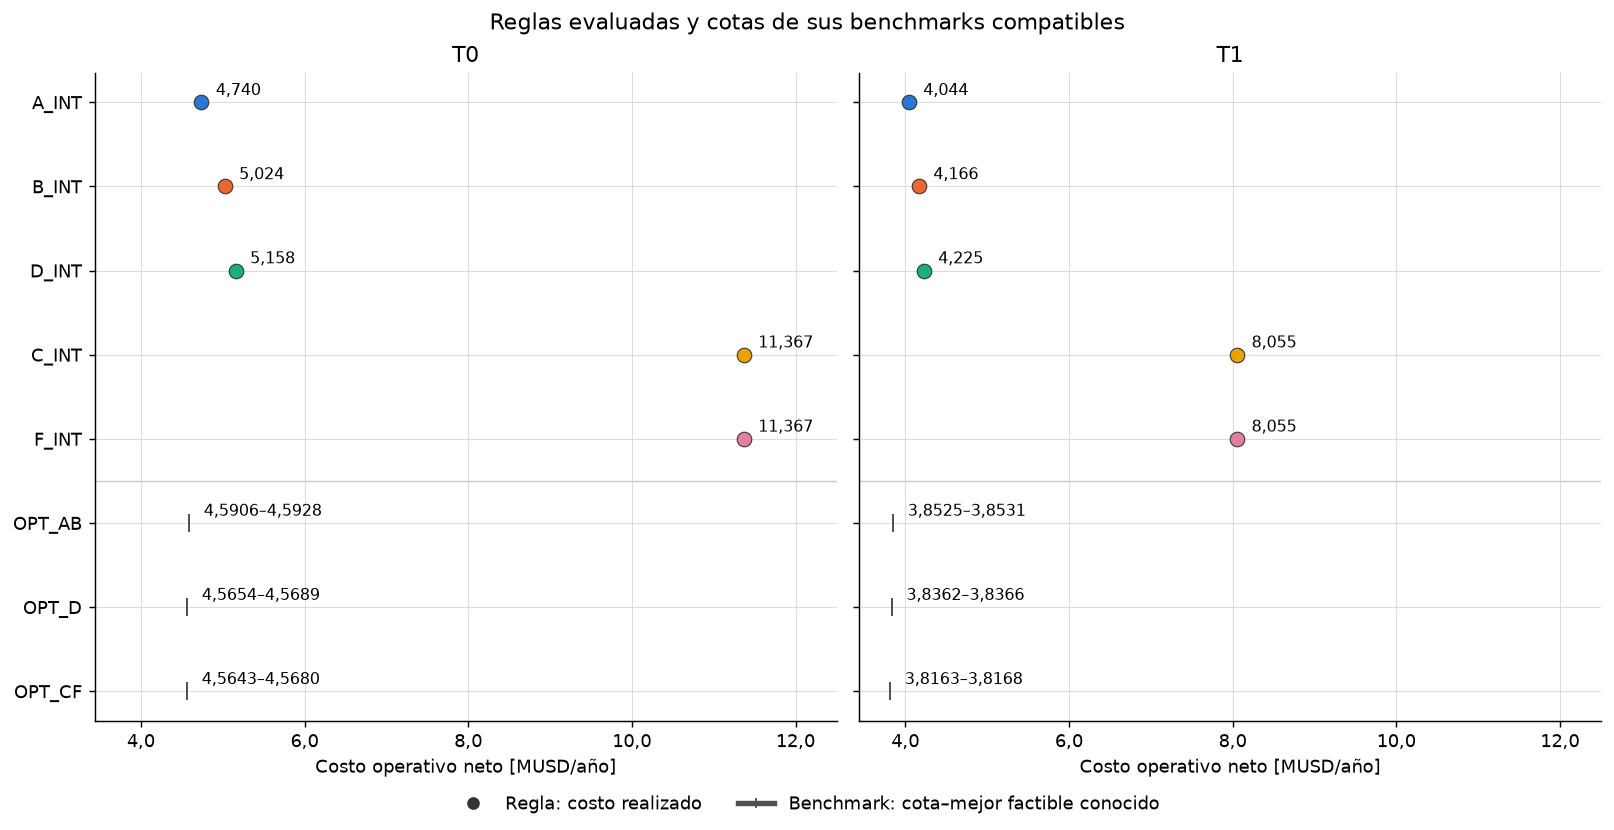

In [11]:
COTAS=[]
for s in SENALES:
    for c in ('OPT_AB','OPT_D','OPT_CF'):
        r=COM.loc[s,c]; upper=r.Costo_USD; origen=c
        if c=='OPT_CF':
            candidates=COM.loc[s].loc[['OPT_CF','OPT_D','C_INT','F_INT'],'Costo_USD']
            origen=candidates.idxmin(); upper=candidates.min()
            saved=GCF[GCF.Senal.eq(s)]
            assert saved.Origen_mejor_factible.eq(origen).all()
            assert np.max(np.abs(saved.Mejor_factible_USD-upper))<=1e-5
        assert r.Cota_USD<=upper+1e-5
        COTAS.append(dict(Senal=s,Benchmark=c,Cota_USD=r.Cota_USD,Costo_solver_USD=r.Costo_USD,
            Mejor_factible_USD=upper,Origen_mejor_factible=origen,Condicion=r.Condicion,
            Brecha_solver_pct=100*r.Brecha_solver))
COTAS=pd.DataFrame(COTAS).set_index(['Senal','Benchmark'])
COTAS.to_csv(OUT/'14_cotas_conjuntas.csv')
tabla(COTAS.reset_index(),4)
filas=[]
for s in SENALES:
    for c in POLITICAS:
        bench='OPT_AB' if c in ('A_INT','B_INT') else ('OPT_D' if c=='D_INT' else 'OPT_CF')
        r=COTAS.loc[s,bench]; costo=COM.loc[s,c].Costo_USD
        lo=max(0.,costo-r.Mejor_factible_USD); hi=max(0.,costo-r.Cota_USD)
        assert r.Cota_USD>0
        filas.append(dict(Senal=s,Politica=c,Benchmark=bench,Costo_USD=costo,
            Distancia_min_USD=lo,Distancia_max_USD=hi,
            Distancia_min_pct=100*lo/r.Mejor_factible_USD,Distancia_max_pct=100*hi/r.Cota_USD))
DIST=pd.DataFrame(filas)
for saved in (GAP,GCF):
    for r in saved.itertuples():
        nuevo=DIST[(DIST.Senal==r.Senal)&(DIST.Politica==r.Politica)].iloc[0]
        for k in ('Distancia_min_USD','Distancia_max_USD','Distancia_min_pct','Distancia_max_pct'):
            assert abs(nuevo[k]-getattr(r,k))<=1e-5
DIST.to_csv(OUT/'14_distancias_conjuntas.csv',index=False)
vista=DIST[['Senal','Politica','Benchmark']].copy()
vista['Distancia [mil USD]']=[intervalo(r.Distancia_min_USD/1000,r.Distancia_max_USD/1000) for r in DIST.itertuples()]
vista['Distancia [%]']=[intervalo(r.Distancia_min_pct,r.Distancia_max_pct) for r in DIST.itertuples()]
tabla(vista)

COLOR_CF={**COLOR,'C_INT':'#eda100','F_INT':'#e87ba4','OPT_CF':'#52514e'}
fig,axs=plt.subplots(1,2,figsize=(12.3,6.3),sharex=True,sharey=True,layout='constrained')
for ax,s in zip(axs,SENALES):
    for j,c in enumerate(CONJUNTOS):
        if c in POLITICAS:
            x=COM.loc[s,c].Costo_USD/1e6
            ax.scatter(x,j,s=65,color=COLOR_CF[c],edgecolor='#333333',linewidths=.6,zorder=3)
            ax.annotate(es(x,3),(x,j),xytext=(8,4),textcoords='offset points',fontsize=9)
        else:
            r=COTAS.loc[s,c]; lo,hi=r.Cota_USD/1e6,r.Mejor_factible_USD/1e6
            ax.plot([lo,hi],[j,j],color=COLOR_CF[c],lw=3,marker='|',ms=10)
            ax.annotate(intervalo(lo,hi,4),(hi,j),xytext=(8,4),textcoords='offset points',fontsize=9)
    ax.axhline(4.5,color='#cccccc',lw=.8)
    ax.set(title=s,xlabel='Costo operativo neto [MUSD/año]',yticks=range(8),yticklabels=CONJUNTOS,xlim=(float(COTAS.Cota_USD.min())/1e6*.90,float(COM.Costo_USD.max())/1e6*1.10))
    ax.xaxis.set_major_formatter(FORMATO)
axs[0].invert_yaxis()
fig.suptitle('Reglas evaluadas y cotas de sus benchmarks compatibles',fontsize=12)
fig.legend(handles=[Line2D([],[],marker='o',color='#333333',ls='',label='Regla: costo realizado'),
    Line2D([],[],color='#52514e',lw=3,marker='|',label='Benchmark: cota–mejor factible conocido')],
    loc='outside lower center',ncol=2,frameon=False)
guardar(fig,'14_5_costos_conjuntos')

### 9.2 · Arranques y rutas de energía

Las figuras siguientes describen las trayectorias guardadas; los benchmarks
conservan sus soluciones del solver. Cada fila utiliza una escala común entre
tarifas. Las descargas no se atribuyen a una fuente cuando existe carga mixta:
el SOC es único y no contiene trazabilidad por origen. El EFC sigue siendo un
indicador de energía entregada, no una estimación de envejecimiento.

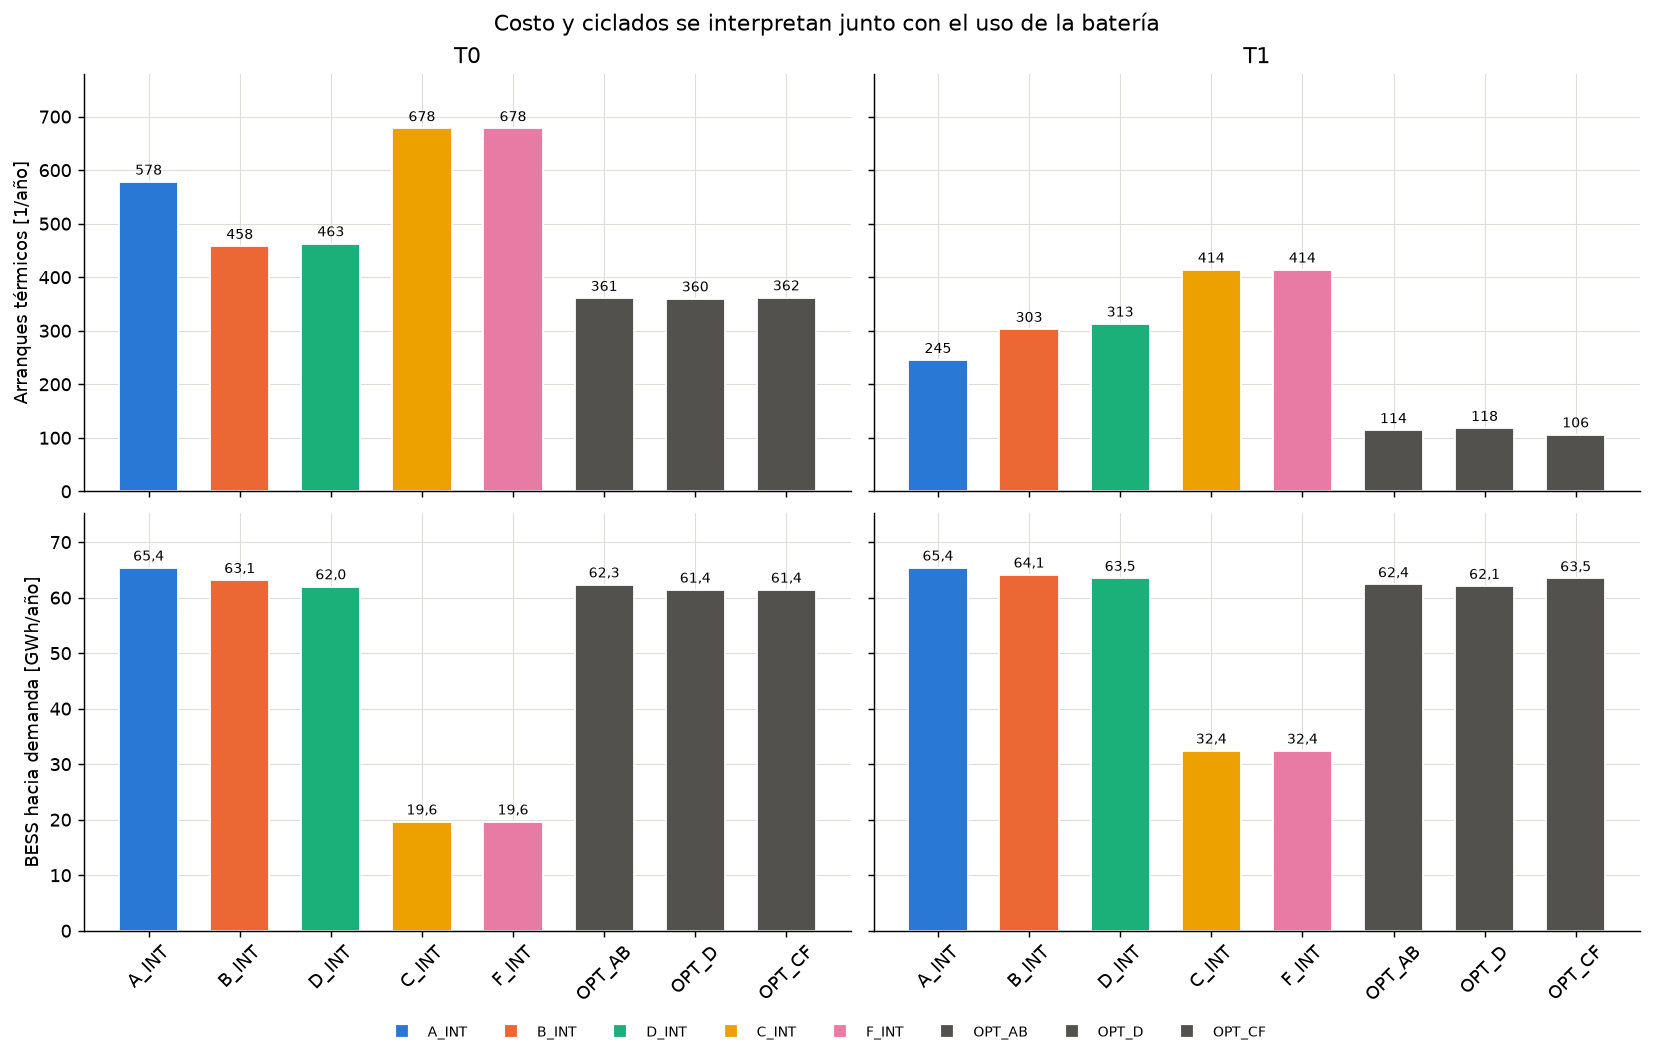

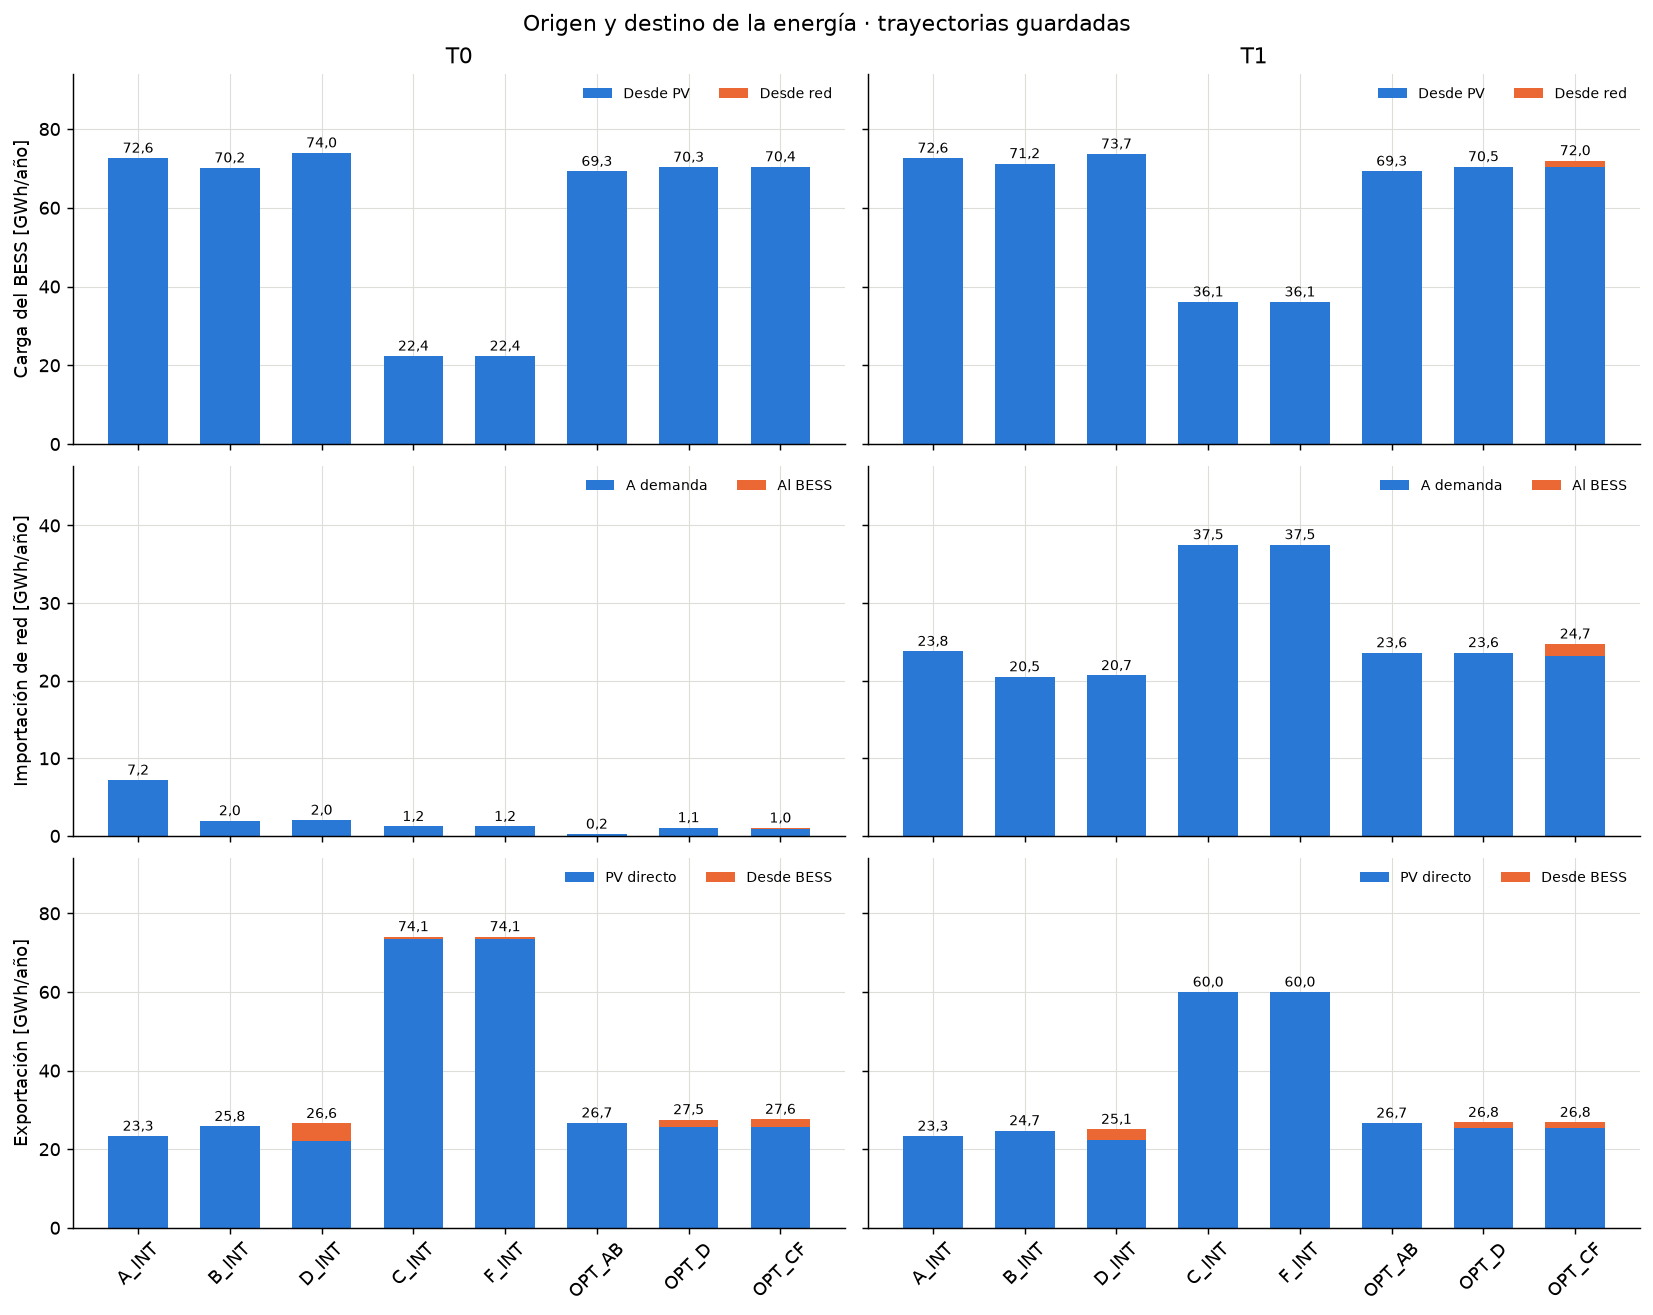

In [12]:
fig,axs=plt.subplots(2,2,figsize=(12.6,8),sharex=True,sharey='row',layout='constrained')
for col,s in enumerate(SENALES):
    r=COM.loc[s].loc[list(CONJUNTOS)]; xs=np.arange(8)
    for row,(key,unit,div) in enumerate([('Arranques','Arranques térmicos [1/año]',1),
                                        ('Descarga_demanda_MWh','BESS hacia demanda [GWh/año]',1000)]):
        ax=axs[row,col]; ys=r[key].to_numpy()/div
        ax.bar(xs,ys,color=[COLOR_CF[c] for c in CONJUNTOS],edgecolor='white',width=.65)
        for x,y in zip(xs,ys): ax.annotate(es(y,0 if row==0 else 1),(x,y),xytext=(0,4),textcoords='offset points',ha='center',fontsize=8)
        ax.set(xticks=xs,xticklabels=CONJUNTOS,title=s if row==0 else None)
        ax.tick_params(axis='x',rotation=45); ax.margins(y=.15)
        if col==0: ax.set_ylabel(unit)
fig.legend(handles=[Line2D([],[],marker='s',color=COLOR_CF[c],ls='',label=c) for c in CONJUNTOS],
    loc='outside lower center',ncol=8,frameon=False,fontsize=8)
fig.suptitle('Costo y ciclados se interpretan junto con el uso de la batería',fontsize=12)
guardar(fig,'14_6_arranques_y_descarga')

fig,axs=plt.subplots(3,2,figsize=(12.6,10),sharex=True,sharey='row',layout='constrained')
rutas=[('Carga_PV_MWh','Carga_red_MWh','Carga del BESS [GWh/año]','Desde PV','Desde red'),
       ('Red_demanda_MWh','Carga_red_MWh','Importación de red [GWh/año]','A demanda','Al BESS'),
       ('Export_PV_MWh','Descarga_export_MWh','Exportación [GWh/año]','PV directo','Desde BESS')]
for col,s in enumerate(SENALES):
    r=COM.loc[s].loc[list(CONJUNTOS)]; xs=np.arange(8)
    for row,(a,b,label,la,lb) in enumerate(rutas):
        ax=axs[row,col]; va=r[a].to_numpy()/1000; vb=r[b].to_numpy()/1000
        ax.bar(xs,va,width=.65,color='#2a78d6',label=la)
        ax.bar(xs,vb,bottom=va,width=.65,color='#eb6834',label=lb)
        for x,y in zip(xs,va+vb): ax.annotate(es(max(0.,y),1),(x,y),xytext=(0,3),textcoords='offset points',ha='center',fontsize=8)
        ax.set(xticks=xs,xticklabels=CONJUNTOS,title=s if row==0 else None)
        ax.tick_params(axis='x',rotation=45); ax.margins(y=.25)
        ax.legend(loc='upper right',fontsize=8,frameon=False,ncol=2)
        if col==0: ax.set_ylabel(label)
for row,(a,b,*_) in enumerate(rutas):
    peak=float((COM[a]+COM[b]).max())/1000
    axs[row,0].set_ylim(0,1.27*peak)
fig.suptitle('Origen y destino de la energía · trayectorias guardadas',fontsize=12)
guardar(fig,'14_7_rutas_energia')

## 10 · Discusión integrada y conclusiones del caso estudiado

El objetivo es comparar políticas del mismo sistema con capacidades fijas.
El bloque principal A/B/D y el adicional C/F mantienen referencias compatibles,
porque habilitar carga desde red cambia las acciones permitidas. Las diferencias
entre reglas son resultados de sus implementaciones, no teoremas sobre las familias.

In [13]:
hallazgos=[]; valor_red=[]
for s in SENALES:
    a,b,c,f=(COM.loc[s,k] for k in ('A_INT','B_INT','C_INT','F_INT'))
    orden=COM.loc[s].loc[list(POLITICAS),'Costo_USD'].sort_values().index.tolist()
    optd=COTAS.loc[s,'OPT_D']; optcf=COTAS.loc[s,'OPT_CF']
    lo=max(0.,optd.Cota_USD-optcf.Mejor_factible_USD)
    hi=max(0.,optd.Mejor_factible_USD-optcf.Cota_USD)
    saved=VCF[VCF.Senal.eq(s)].iloc[0]
    assert abs(lo-saved.Valor_min_USD)<1e-5 and abs(hi-saved.Valor_max_USD)<1e-5
    valor_red.append(dict(Senal=s,Valor_min_USD=lo,Valor_max_USD=hi,
        Carga_red_solver_OPT_CF_MWh=COM.loc[s,'OPT_CF'].Carga_red_MWh,
        Origen_mejor_factible=optcf.Origen_mejor_factible))
    hallazgos.append(f'**{s}.** Orden de costo: {", ".join(orden)}. '
        f'A_INT cuesta {es(a.Costo_USD/1e6,4)} MUSD/año. '
        f'Diferencia B − A: {es(b.Costo_USD-a.Costo_USD)} USD y {int(b.Arranques-a.Arranques):+d} arranques. '
        f'C/F coinciden hora a hora: {CF_IDENTICAS[s]}. Carga desde red de C/F: '
        f'{es(c.Carga_red_MWh)} / {es(f.Carga_red_MWh)} MWh. Descarga a demanda C/F: '
        f'{es(c.Descarga_demanda_MWh/1000)} / {es(f.Descarga_demanda_MWh/1000)} GWh. '
        f'El valor óptimo de habilitar carga desde red está entre {intervalo(lo,hi)} USD/año.')

display(Markdown('\n\n'.join(hallazgos)))
pd.DataFrame(valor_red).to_csv(OUT/'14_valor_carga_red.csv',index=False)

**T0.** Orden de costo: A_INT, B_INT, D_INT, C_INT, F_INT. A_INT cuesta 4,7396 MUSD/año. Diferencia B − A: 284.070,47 USD y -120 arranques. C/F coinciden hora a hora: True. Carga desde red de C/F: 0,00 / 0,00 MWh. Descarga a demanda C/F: 19,64 / 19,64 GWh. El valor óptimo de habilitar carga desde red está entre 0,00–4.515,83 USD/año.

**T1.** Orden de costo: A_INT, B_INT, D_INT, C_INT, F_INT. A_INT cuesta 4,0439 MUSD/año. Diferencia B − A: 122.640,17 USD y +58 arranques. C/F coinciden hora a hora: False. Carga desde red de C/F: 52,79 / 39,70 MWh. Descarga a demanda C/F: 32,42 / 32,40 GWh. El valor óptimo de habilitar carga desde red está entre 19.557,83–20.286,61 USD/año.

**Resultado económico y operativo.** La clasificación y las diferencias anteriores
se calculan desde los resultados de este escenario. Se interpretan junto con arranques,
uso del BESS y balance de ingresos; una reducción de eventos no equivale a un costo
de mantenimiento calibrado. El cargo de 100 USD/arranque permanece como supuesto.

**Exportación y carga desde red.** La diferencia D − B mide el resultado de las
implementaciones heurísticas. Las diferencias entre benchmarks compatibles acotan
el valor potencial de habilitar rutas adicionales. Cuando el intervalo incluye cero,
la precisión disponible no permite afirmar un beneficio estrictamente positivo.
Si el solver de un conjunto más amplio entrega un costo peor, se utiliza una solución
factible conocida de su subconjunto y se identifica su procedencia.

**C/F y utilización del BESS.** Se informa su coincidencia o diferencia, la compra
efectiva para el BESS y la descarga hacia demanda. Las horas con SOC disponible y
déficit sin descarga son un diagnóstico descriptivo: no demuestran que descargar
en cada una mejoraría el costo total. No se ajustan reglas para imponer un ranking.

**Alcance.** Tamaños fijos; demanda anual y perfil solar TMY; información diaria
según la política y anual perfecta en los benchmarks; compromiso térmico heredado
entre días. Solo el BESS es cíclico. Se verifican cierres sin consumo neto del inventario
inicial. El estudio no calibra rampas, arranques reales o vida útil, ni estima VPN en
este despacho. La validez física no convierte una heurística en óptimo.

Las conclusiones del escenario de gas 16 conservadas en el manuscrito y la discusión
histórica deben distinguirse de las cifras de este cuaderno. La comparación vigente
se respalda en sus nuevas tablas, figuras y trazabilidad.

In [14]:
assert all(hashlib.sha256(Path(p).read_bytes()).hexdigest()==h for p,h in HASHES.items())
assert all(AUD_TOTAL.Estado.eq('OK'))
registro=dict(cuaderno='14_Comparacion_anual_reglas_integradas.ipynb',horas=8760,
    fuentes_sha256=HASHES,casos_integrados=16,referencias_sin_bess=2,pertenencias_previas=12,
    validaciones_lectura=18,figuras=FIGURAS,semana_inicio=str(inicio),
    seleccion_semana='Semana completa lunes-domingo más cercana a la mediana de energía PV; primer empate.',
    gas_USD_MMBtu=P['gas'],CVOM_USD_MWh=P['cvom'].tolist(),TRM_COP_USD=META['TRM'],
    convencion_EFC='Descarga total entregada AC / capacidad útil nominal (224 MWh).',
    fuentes_sin_modificar=True,optimizaciones_ejecutadas=0)
(OUT/'14_trazabilidad.json').write_text(json.dumps(registro,ensure_ascii=False,indent=2),encoding='utf-8')
print(f'Cierre: 18 validaciones OK; 12 pertenencias previas OK; {len(FIGURAS)} figuras PNG/SVG; fuentes intactas; 0 optimizaciones.')

Cierre: 18 validaciones OK; 12 pertenencias previas OK; 8 figuras PNG/SVG; fuentes intactas; 0 optimizaciones.


## 11 · Comparación factorial anual con térmica

Se contrasta si el orden de las reglas se conserva en K1–K4 y T0/T1, con el mismo
recurso solar, demanda, gas y CVOM. Son 40 políticas, 24 benchmarks y ocho referencias
únicas. K combina PV, potencia y energía del BESS: se trata como factor categórico,
sin atribuir su efecto exclusivamente a la capacidad de batería.

El lector verifica los hashes de los resultados completos. No importa modelos,
no ejecuta nuevas optimizaciones ni altera los archivos de las corridas.

**Configuraciones congeladas**

| K | PV [MWp] | PV anual / demanda | BESS [MW/MWh] |
|---|---|---|---|
| K1 | 114,42 | 100,0 % | 50 / 400 |
| K2 | 105,03 | 91,8 % | 45 / 180 |
| K3 | 114,42 | 100,0 % | 45 / 280 |
| K4 | 94,96 | 83,0 % | 50 / 100 |

**Costo operativo neto [mil millones COP/año]**

| K / tarifa | A | B | D | C | F | Menor costo |
|---|---|---|---|---|---|---|
| K1 / T0 | 10,91 | 13,28 | 13,84 | 35,53 | 35,53 | A |
| K2 / T0 | 26,40 | 26,23 | 26,20 | 38,08 | 38,09 | D |
| K3 / T0 | 14,82 | 15,70 | 16,12 | 35,53 | 35,53 | A |
| K4 / T0 | 38,26 | 38,08 | 38,03 | 41,76 | 41,77 | D |
| K1 / T1 | 9,27 | 10,38 | 10,83 | 24,82 | 24,82 | A |
| K2 / T1 | 22,97 | 22,88 | 22,88 | 29,22 | 29,23 | D |
| K3 / T1 | 12,64 | 13,02 | 13,21 | 25,18 | 25,18 | A |
| K4 / T1 | 34,17 | 33,78 | 33,76 | 35,67 | 35,71 | D |

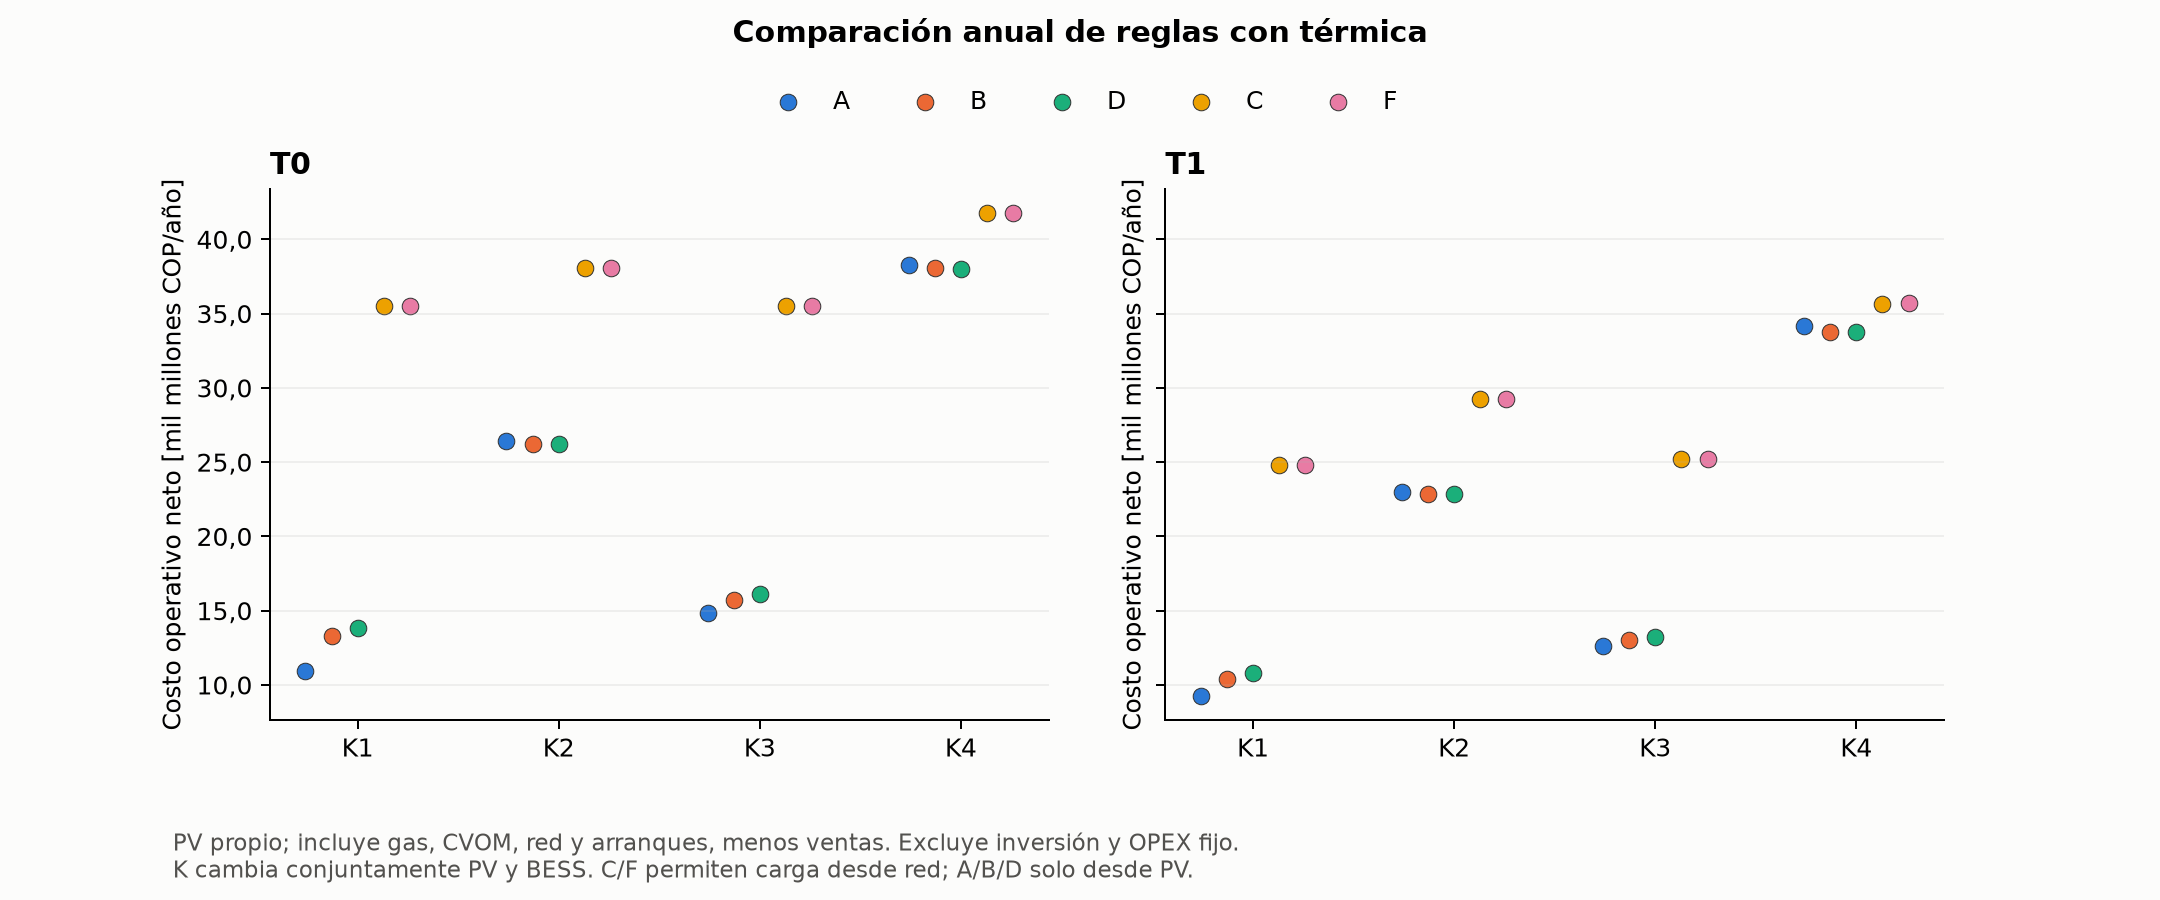

In [15]:
sys.path.insert(0,str(Path.cwd()/'.build'))
from ampliacion_tesis import generar, FACTORIAL, VPN
AMP, EXACTOS_AMP, FUENTES_AMP = generar(Path.cwd())
from IPython.display import Image
display(Markdown('**Configuraciones congeladas**\n\n'+AMP['FACTORIAL_CONFIG']))
display(Markdown('**Costo operativo neto [mil millones COP/año]**\n\n'+AMP['FACTORIAL_COSTOS']))
display(Image(filename=str(FACTORIAL/'figuras/01_costos_reglas.png')))

A tiene el menor costo en K1/K3; D en K2/K4, bajo ambas tarifas. La ventaja de D frente a A en K2/K4 es de 0,40–1,19 %. Son diferencias entre trayectorias heurísticas calculadas; la brecha del solver afecta su distancia al benchmark, no ese orden entre reglas.

,K,Senal,Caso,Benchmark,Distancia mínima [millones COP/año],Distancia máxima [millones COP/año]
0,K1,T0,A_INT,OPT_AB,"581,13","590,36"
1,K1,T0,B_INT,OPT_AB,"2.948,74","2.957,97"
2,K1,T0,D_INT,OPT_D,"3.649,10","3.657,97"
3,K1,T0,C_INT,OPT_CF,"25.333,05","25.343,02"
4,K1,T0,F_INT,OPT_CF,"25.333,05","25.343,02"
5,K1,T1,A_INT,OPT_AB,"740,74","741,47"
6,K1,T1,B_INT,OPT_AB,"1.853,39","1.854,12"
7,K1,T1,D_INT,OPT_D,"2.417,42","2.419,48"
8,K1,T1,C_INT,OPT_CF,"16.468,47","16.470,52"
9,K1,T1,F_INT,OPT_CF,"16.468,73","16.470,79"


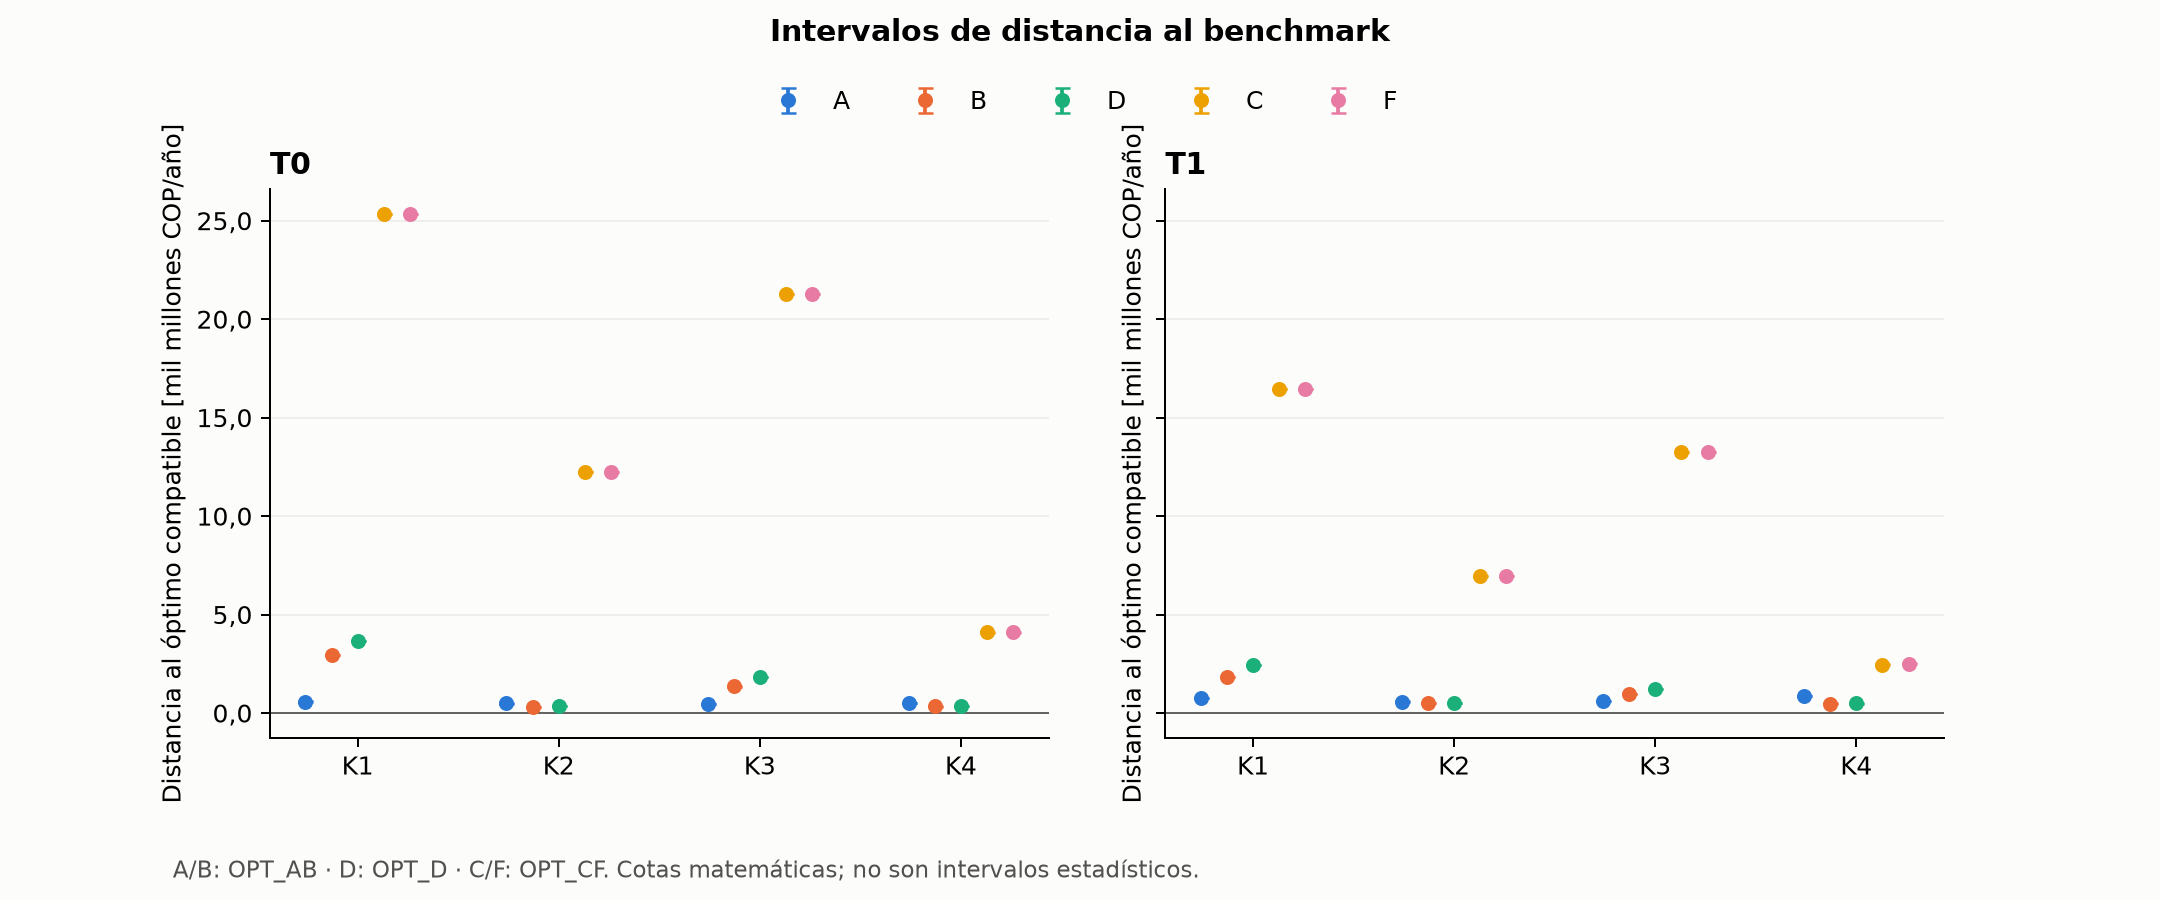

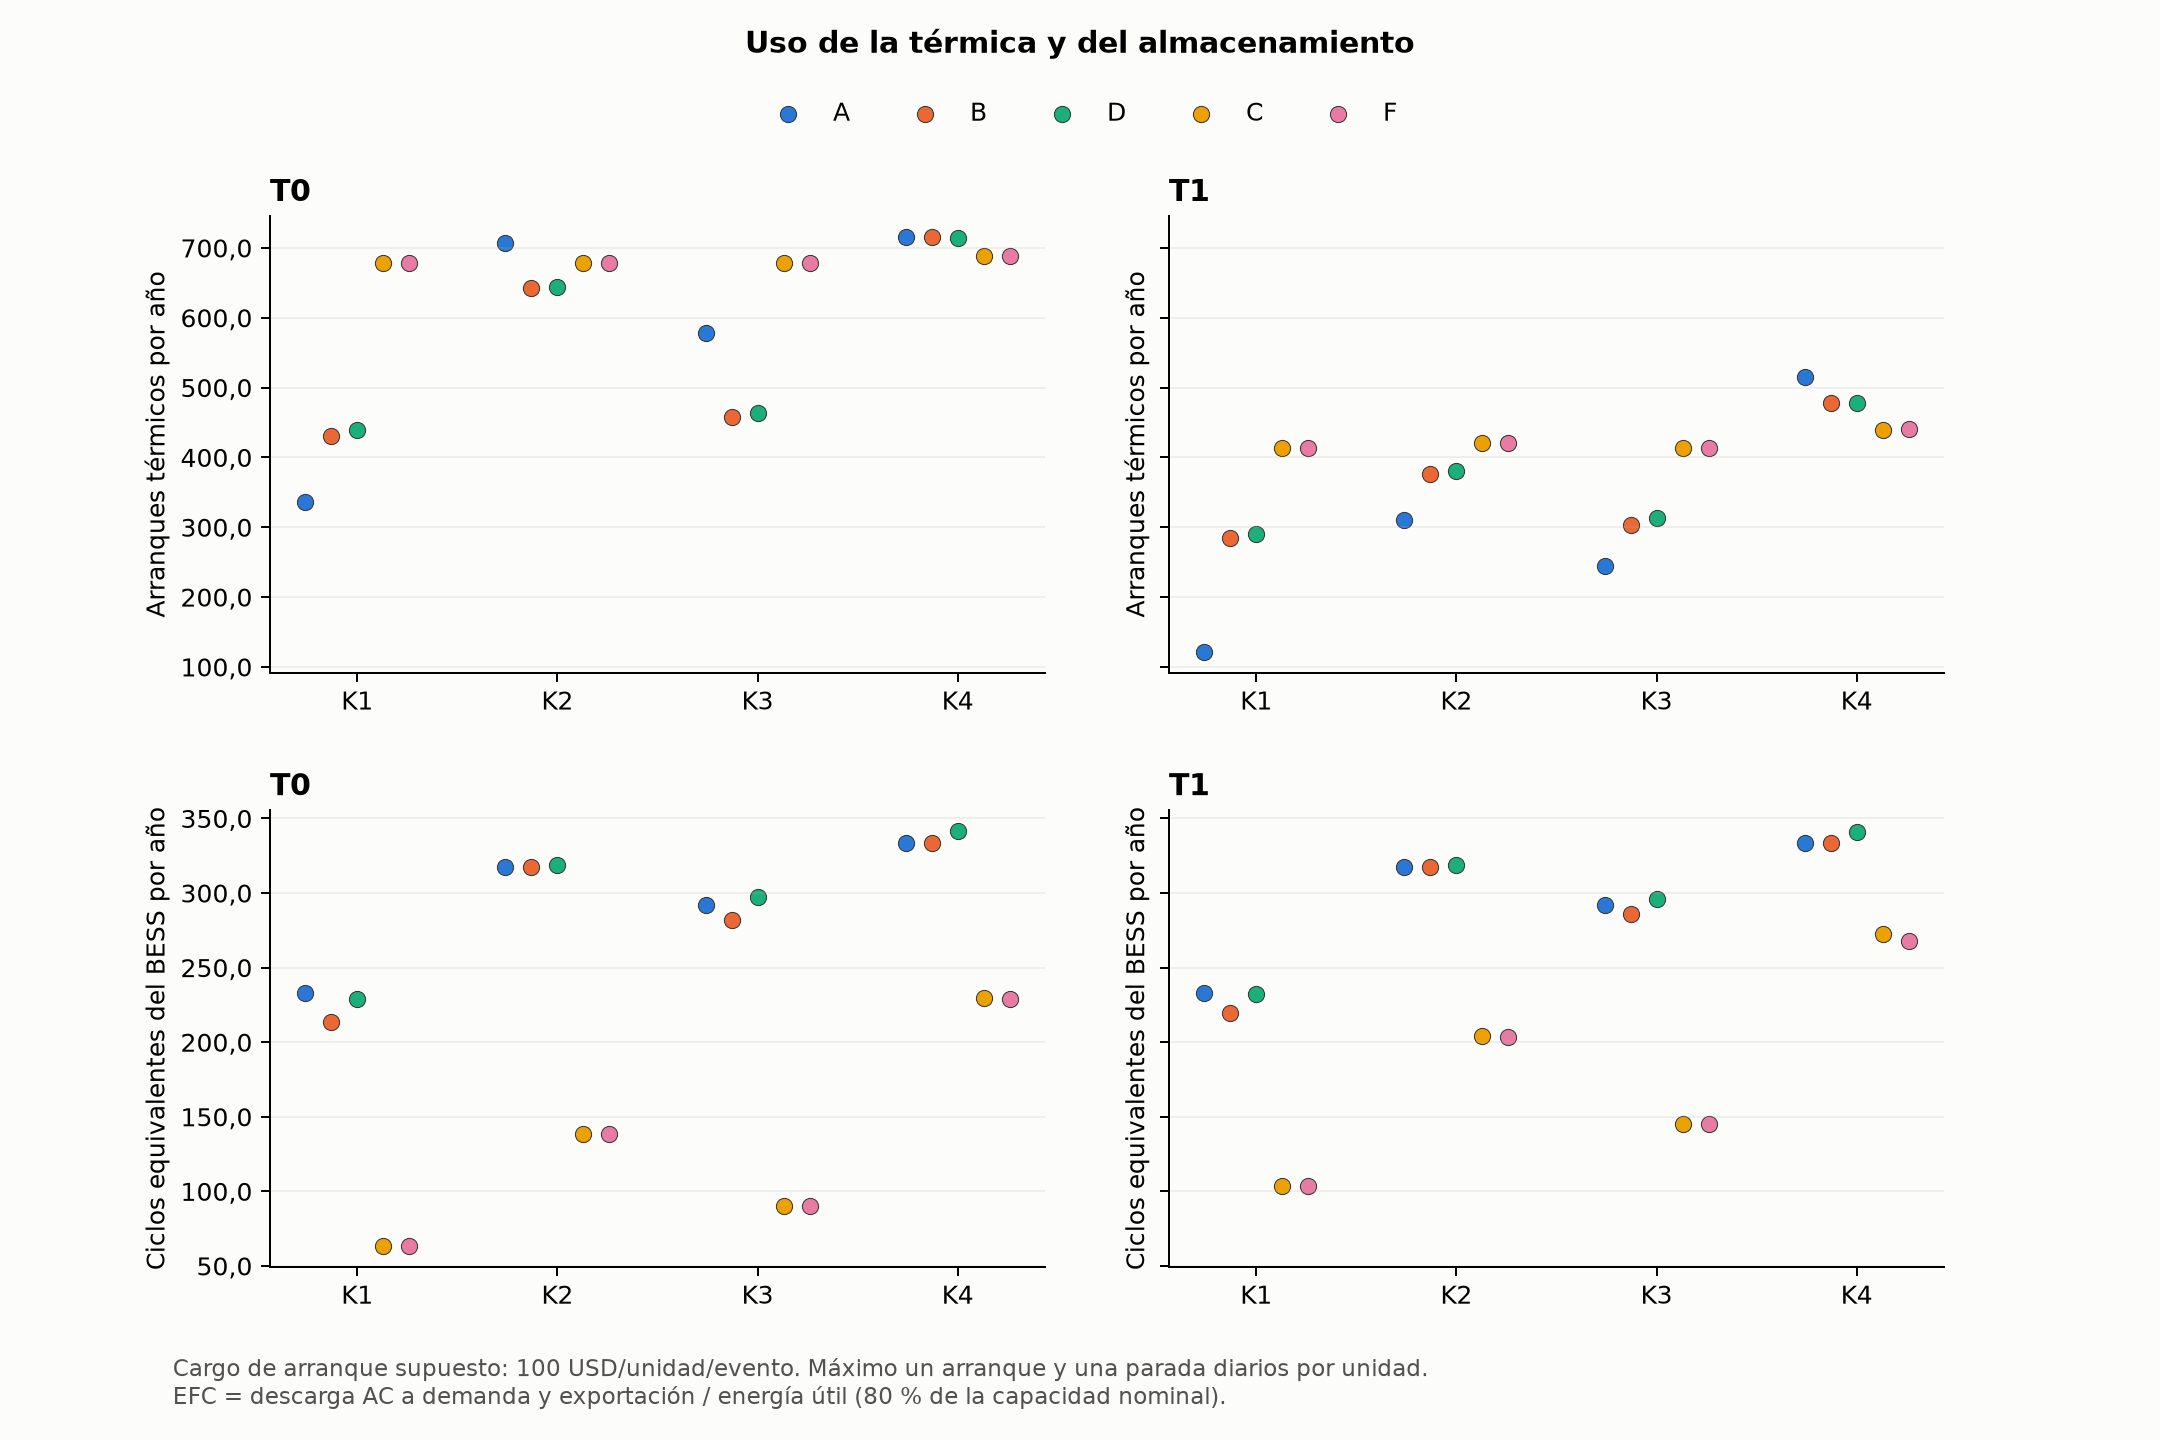

,Efecto,Suma_cuadrados_USD2,Fraccion_pct
0,Configuracion,229820078096332.281250,96.948
1,Tarifa,6190878303559.957031,2.612
2,Regla,201662605157.725769,0.085
3,Configuracion × Tarifa,291524808379.436584,0.123
4,Configuracion × Regla,476256557980.006897,0.201
5,Tarifa × Regla,35390501093.131149,0.015
6,Configuracion × Tarifa × Regla,39675906235.831268,0.017


In [16]:
display(Markdown('A tiene el menor costo en K1/K3; D en K2/K4, bajo ambas tarifas. '
    'La ventaja de D frente a A en K2/K4 es de '+AMP['VENTAJA_D_MIN']+'–'+AMP['VENTAJA_D_MAX']+
    ' %. Son diferencias entre trayectorias heurísticas calculadas; la brecha del solver afecta '
    'su distancia al benchmark, no ese orden entre reglas.'))
fac_comp=pd.read_csv(FACTORIAL/'comparacion.csv')
fac_comp['Distancia mínima [millones COP/año]']=fac_comp.Distancia_min_USD*META['TRM']/1e6
fac_comp['Distancia máxima [millones COP/año]']=fac_comp.Distancia_max_USD*META['TRM']/1e6
display(fac_comp[['K','Senal','Caso','Benchmark','Distancia mínima [millones COP/año]',
                  'Distancia máxima [millones COP/año]']].style.format(precision=2,decimal=',',thousands='.'))
display(Image(filename=str(FACTORIAL/'figuras/02_distancia_benchmarks.png')))
display(Image(filename=str(FACTORIAL/'figuras/03_arranques_ciclos.png')))
display(pd.read_csv(FACTORIAL/'descomposicion_ABD.csv').style.format({'Fraccion_pct':'{:.3f}'}))

**Interpretación.** Una menor importación no garantiza menor costo: puede acompañarse
de más combustible y CVOM. En K1, la descarga inmediata de A reduce más el suministro
residual; los mayores ingresos de D no compensan sus costos adicionales. En K2/K4,
la combinación de red, térmica y exportación de D produce una ventaja pequeña.
Esta lectura contable explica las diferencias observadas; no prueba el efecto aislado
de la exportación o de la capacidad. Las reglas conservan sus horizontes y limitaciones.

K domina la variación del costo absoluto de A/B/D, pero incluye recursos e inversiones
distintos. La descomposición es descriptiva, sin réplicas ni p-valores. No mide la
irrelevancia económica de elegir una regla ni demuestra un tamaño óptimo.

Dos benchmarks K2/T0 terminaron por tiempo: OPT_D (0,135 %) y OPT_CF (0,467 %).
Se conservan sus cotas. Una solución factible no se presenta como óptimo exacto.

## 12 · Comparación financiera de K3 durante veinte años

Esta sección añade inversión, OPEX fijo y renovación del almacenamiento a **K3**.
Cada una de las veinte anualidades tiene despacho horario explícito. La producción
PV disminuye 0,5 % anual; demanda, tarifas, gas y CVOM se mantienen en términos reales.
Tasa real de descuento del 10 %, sin impuestos, financiación, incentivos ni valor residual.

El VPN total compara PV+BESS con red+térmica; el incremental del BESS compara el
mismo PV con y sin batería. La térmica existente no añade inversión. El CAPEX es
común a las reglas; el OPEX fijo es 2 % del CAPEX PV y 1,5 % del CAPEX BESS por año.
La renovación se evalúa con 7.200 EFC o veinte años, sin reposición al cierre exacto.
No se modela pérdida progresiva de capacidad del BESS.

**Inversión [mil millones COP]:** PV 240,64, BESS 157,61, total 398,26.

**VPN [mil millones COP reales]**

| Regla | T0 total | T0 BESS | T1 total | T1 BESS |
|---|---|---|---|---|
| A | 259,49 | 81,48 | 209,49 | 60,14 |
| B | 252,73 | 74,72 | 206,58 | 57,24 |
| D | 249,25 | 71,24 | 205,15 | 55,81 |
| C | 88,72 | -89,29 | 106,13 | -43,22 |
| F | 88,72 | -89,29 | 106,12 | -43,23 |

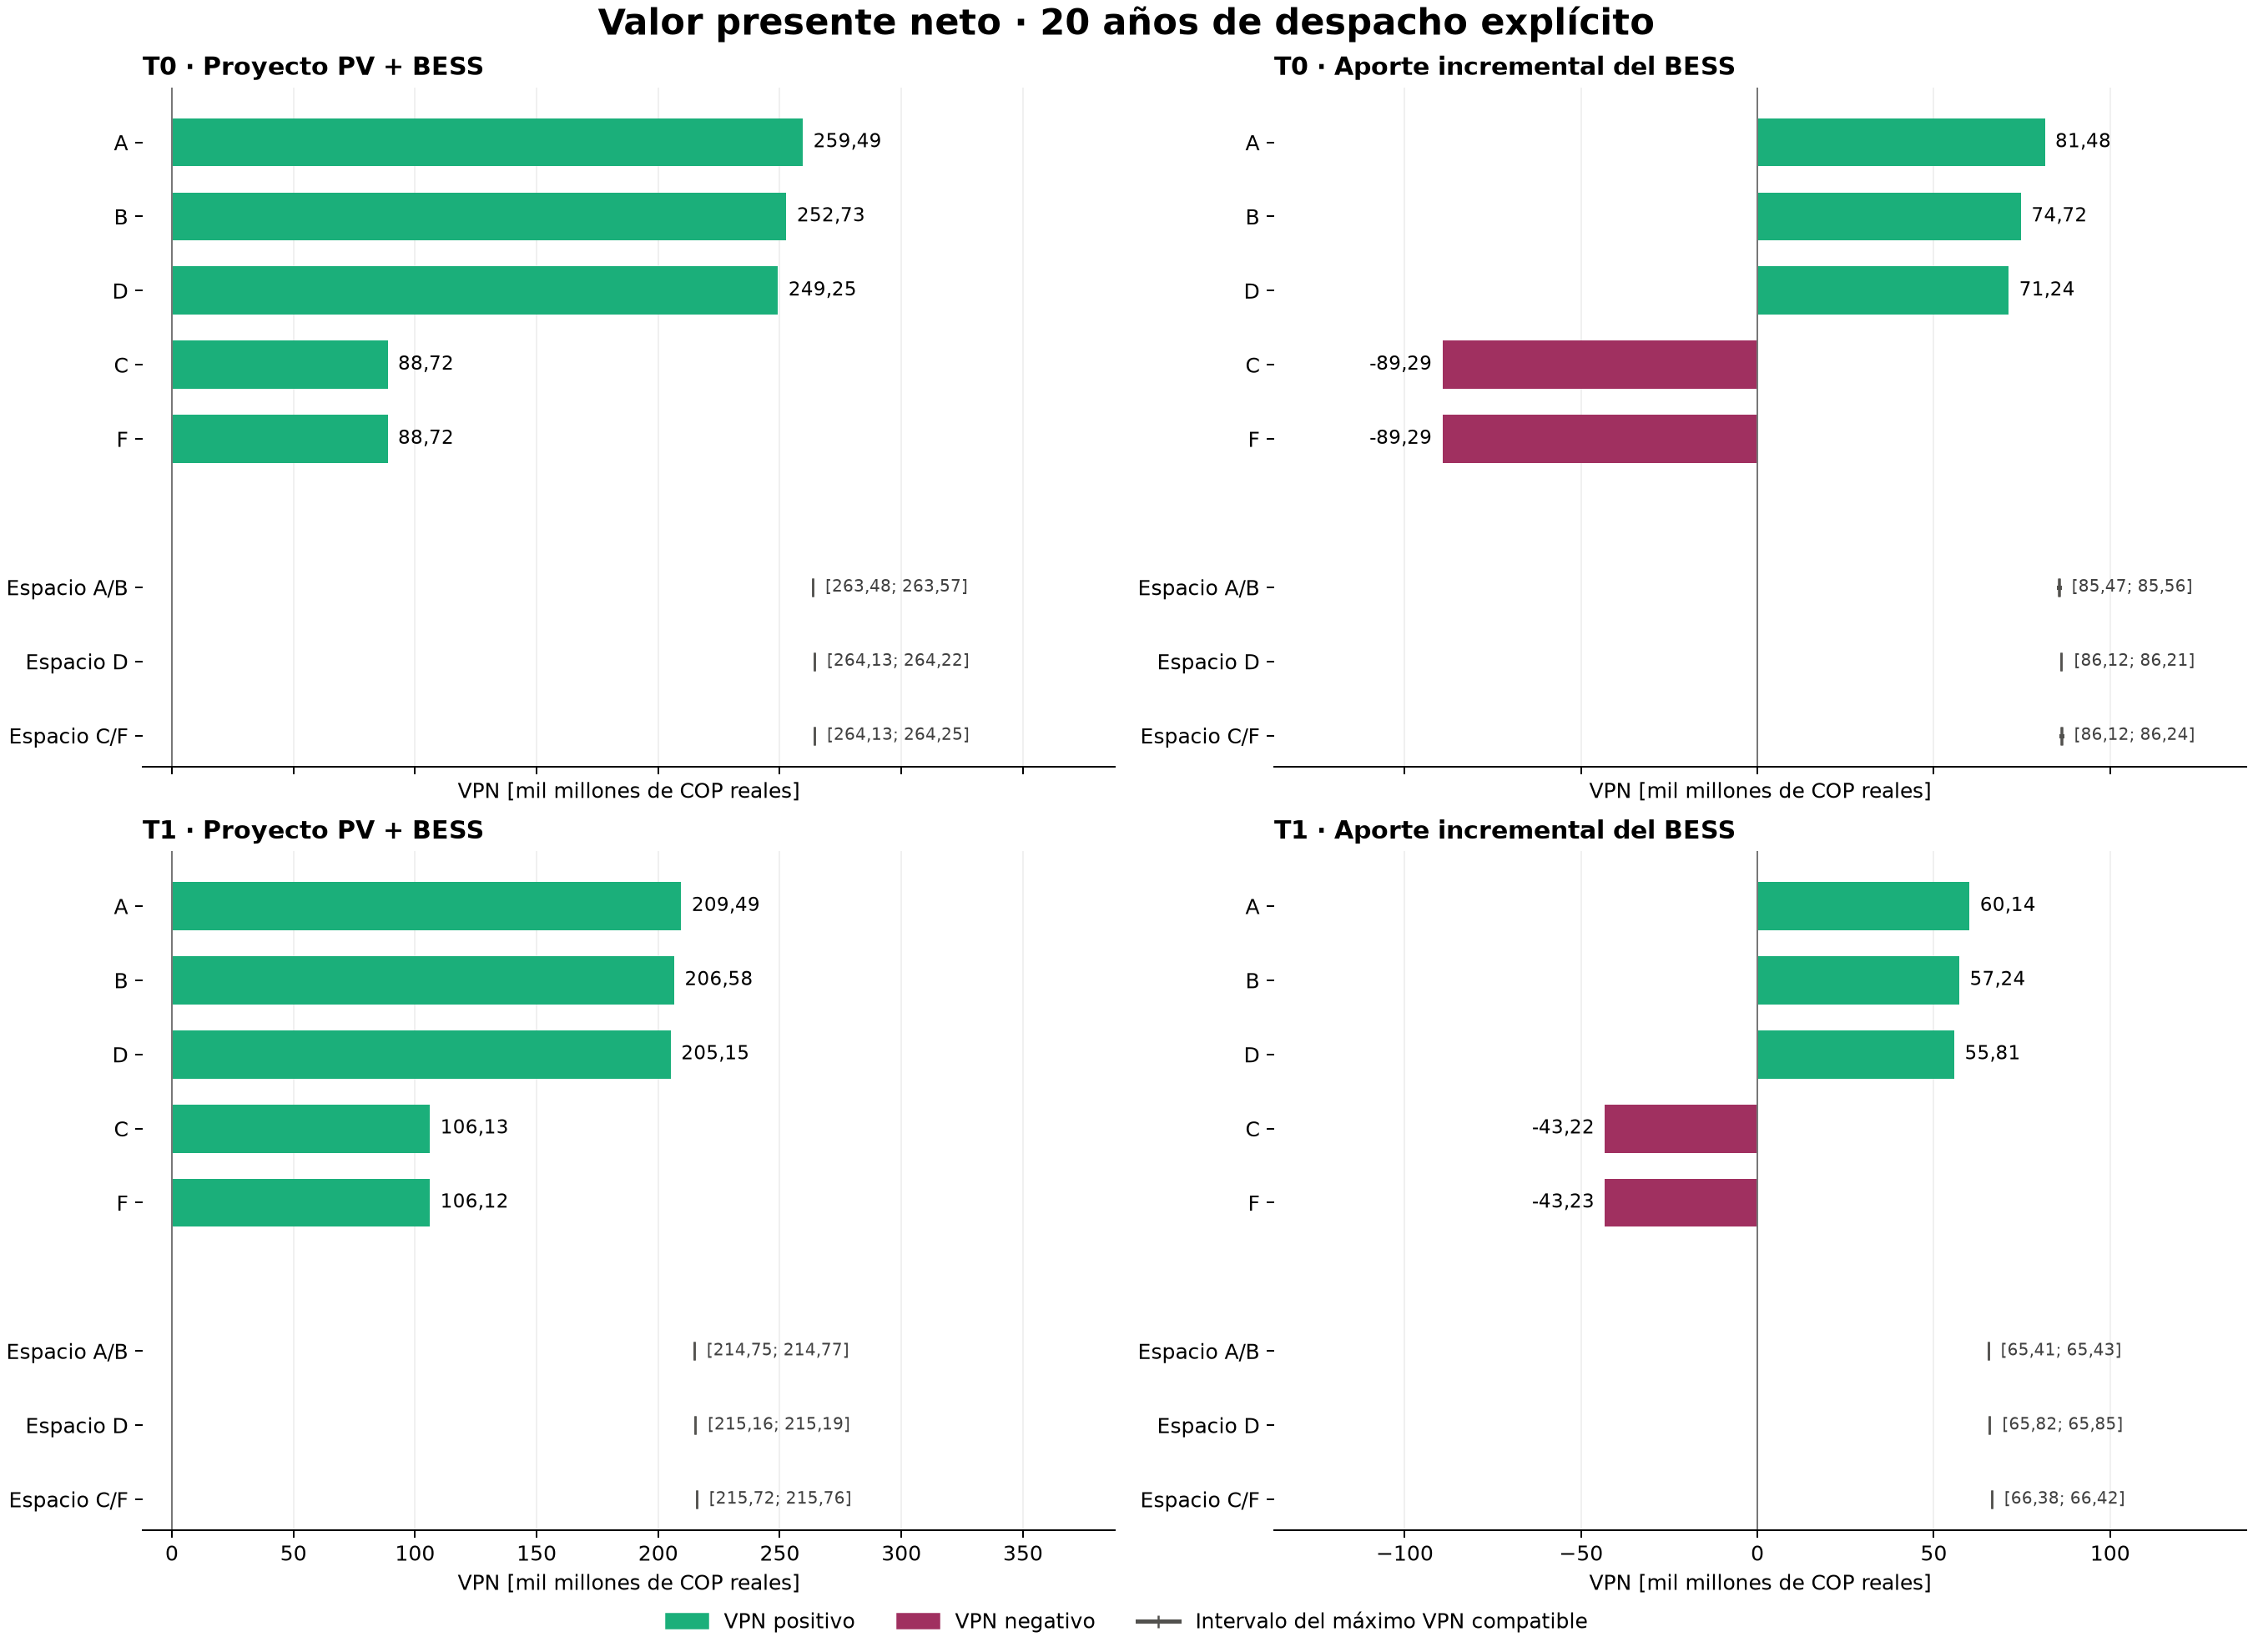

**Intervalos del VPN incremental compatible [mil millones COP]**

| Espacio compatible | T0 VPN BESS | T1 VPN BESS |
|---|---|---|
| OPT_AB | [85,47; 85,56] | [65,40; 65,43] |
| OPT_D | [86,11; 86,21] | [65,81; 65,85] |
| OPT_CF | [86,11; 86,24] | [66,37; 66,42] |

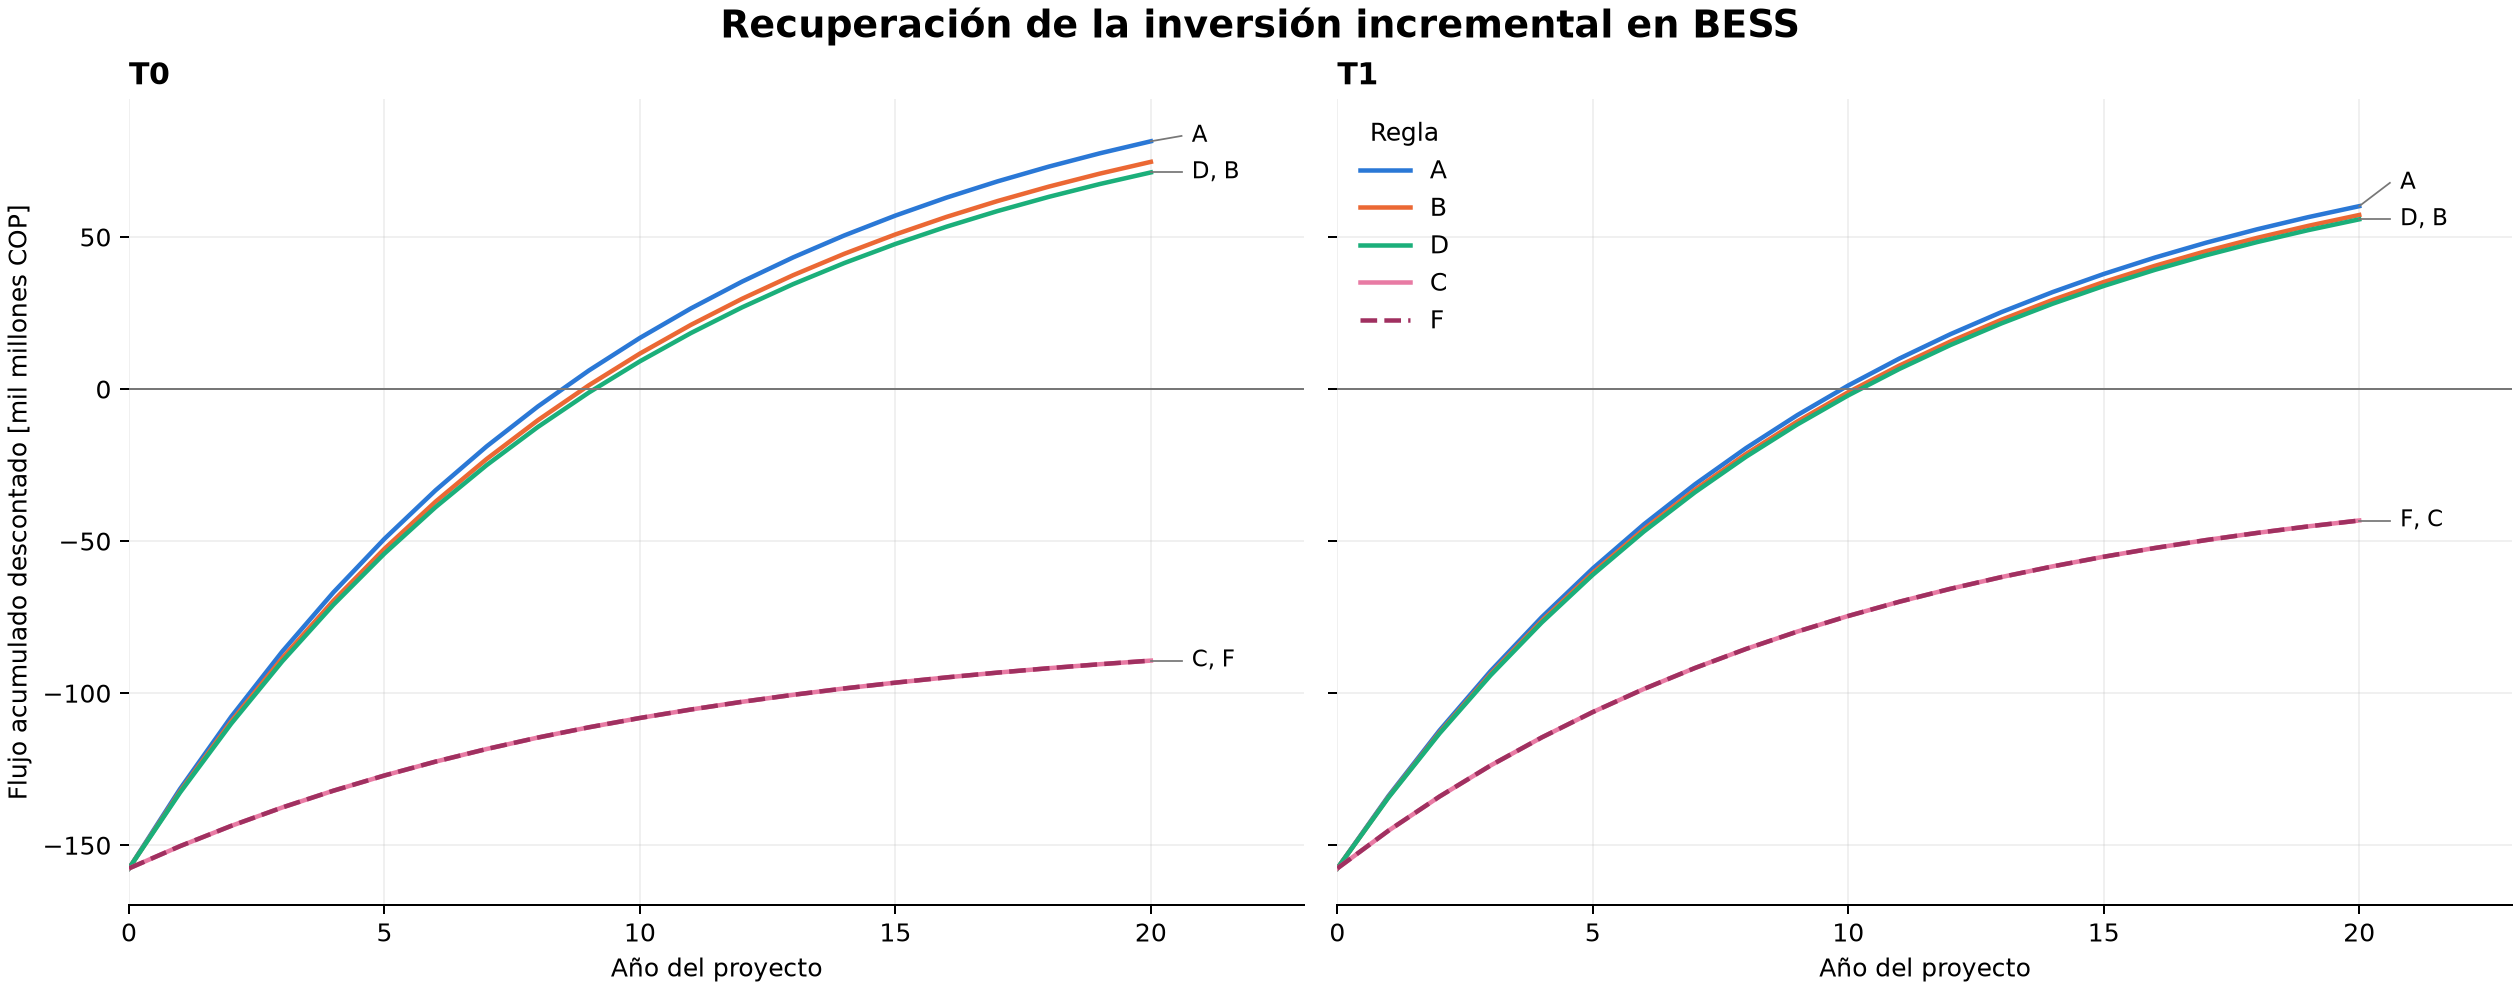

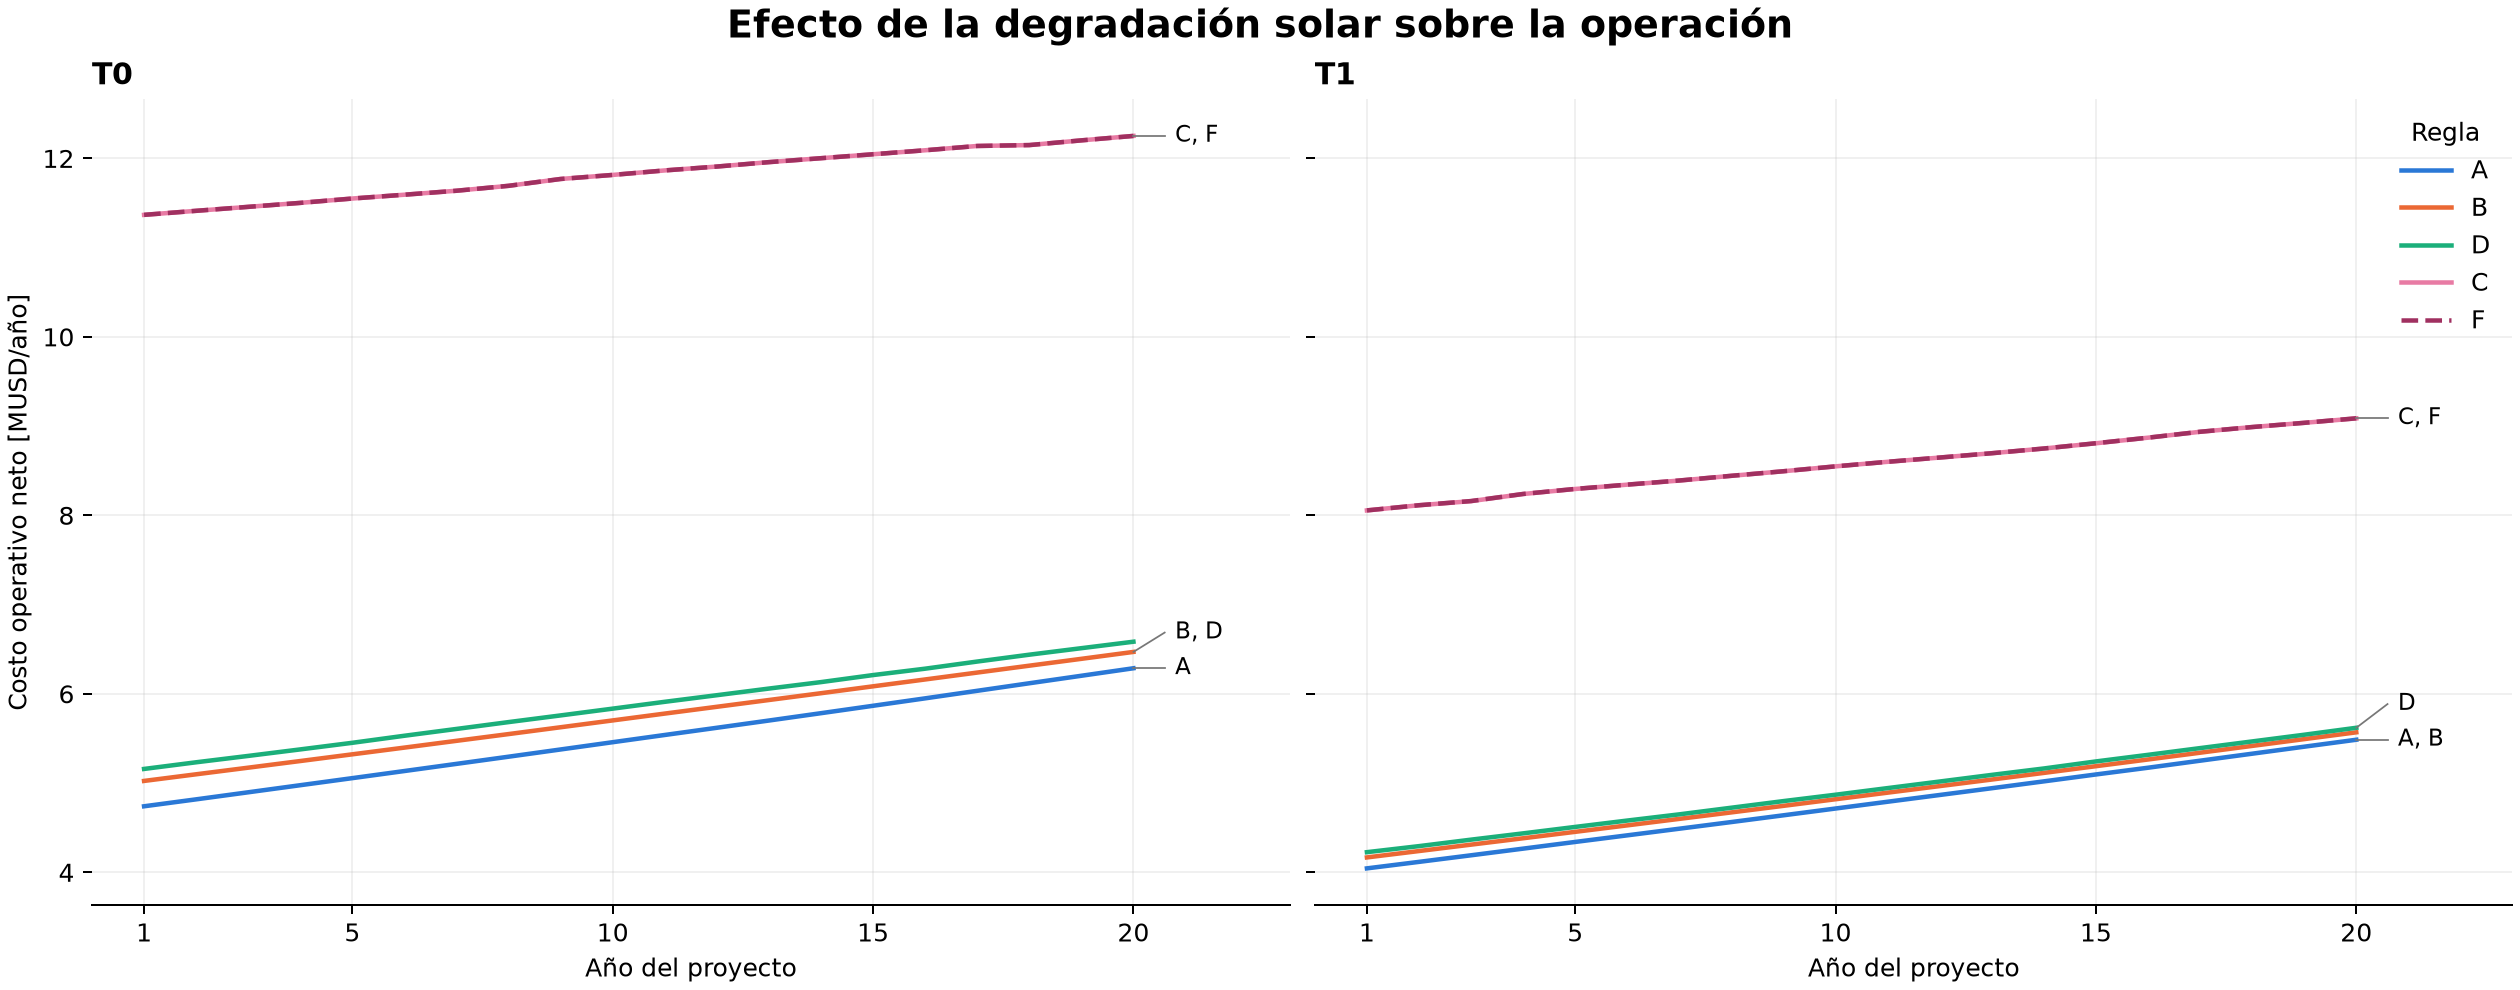

In [17]:
display(Markdown('**Inversión [mil millones COP]:** PV '+AMP['CAPEX_PV']+', BESS '+AMP['CAPEX_BESS']+
    ', total '+AMP['CAPEX_TOTAL']+'.\n\n**VPN [mil millones COP reales]**\n\n'+AMP['VPN_TABLA']))
display(Image(filename=str(VPN/'figuras/01_vpn_total_incremental.png')))
display(Markdown('**Intervalos del VPN incremental compatible [mil millones COP]**\n\n'+AMP['VPN_BANDAS']))
display(Image(filename=str(VPN/'figuras/02_recuperacion_bess.png')))
display(Image(filename=str(VPN/'figuras/03_costos_anuales.png')))

**Resultado.** A obtiene el mayor VPN entre las cinco reglas en K3. A/B/D crean valor
incremental del BESS bajo ambas tarifas. C/F tienen VPN total positivo, pero VPN
incremental negativo: la rentabilidad del PV no justifica añadir la batería bajo
cualquier regla. Ninguna trayectoria alcanza una renovación antes de cerrar el horizonte.

**Benchmarks.** PyPSA minimiza costo operativo anual; su VPN no se declara máximo
financiero. Los intervalos usan el mejor VPN factible compatible como cota inferior
y las cotas operativas, sin costo de renovación no negativo, como cota superior.
Cada año tiene SOC cíclico propio y estado térmico inicial libre. No es una trayectoria
continua de compromiso durante veinte años ni un pronóstico de precios.

**Conclusión conjunta.** No hay una regla ganadora para todas las configuraciones
operativas evaluadas. En K3, A también lidera el criterio financiero. El factorial
no permite extrapolar ese VPN a K1/K2/K4 ni seleccionar una inversión óptima.

In [18]:
assert all(hashlib.sha256(Path(p).read_bytes()).hexdigest()==h for p,h in FUENTES_AMP.items())
(OUT/'14_ampliacion_trazabilidad.json').write_text(json.dumps(dict(
    factorial_casos=72,vpn_despachos=362,vpn_evaluaciones=34,flujos=680,
    fuentes_sha256=FUENTES_AMP,valores_prosa=EXACTOS_AMP,optimizaciones_ejecutadas=0),
    ensure_ascii=False,indent=2),encoding='utf-8')
print('Ampliación completa: factorial y VPN validados desde archivos; cero optimizaciones.')

Ampliación completa: factorial y VPN validados desde archivos; cero optimizaciones.
